# 🗓️ Zeitplanung Optimieren – Genetischer Algorithmus
### Masterkurs: Programmierkonzepte und Algorithmen
### Datensatz: `task_scheduling.json` (Game of Thrones Council Scheduling)

---

## Problemdefinition (aus dem Datensatz)

| Dimension | Details |
|---|---|
| **9 Aufgaben (Tasks)** | War Council, Alliance Negotiation, Wight Recon, … |
| **25 Teilnehmer (Characters)** | Jon Snow, Daenerys, Tyrion, … |
| **10 Zeitslots** | Day1_AM … Day5_PM |
| **10 Orte** | Dragonstone, Winterfell, King's Landing, … |

**Ziel**: Weise jeder Aufgabe einen Zeitslot, einen Ort und eine Gruppe von Teilnehmern zu,  
sodass der **Gesamtscore** (Fitness) maximiert wird.

**Fitness basiert exakt auf `scoring_suggestion` aus dem JSON:**
- ✅ Basis-Wert pro erledigter Aufgabe
- ✅ Boni: bevorzugte Personen / Orte / Zeitslots / Sympathie-Paare
- ❌ Strafen: fehlende Pflichtpersonen / verbotene Personen / Doppelbuchungen / falsche Orte


In [1]:
import json, random, copy, time, warnings, logging
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import multiprocessing as mp
from itertools import combinations
from typing import List, Dict, Tuple, Optional, Set
from dataclasses import dataclass, field
from collections import Counter
import logging

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s"
)
logger = logging.getLogger("island_worker")

warnings.filterwarnings('ignore')
RANDOM_SEED = 43
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s"
)
logger = logging.getLogger("ga_notebook")

print("✅ Bibliotheken geladen")
print(f"   CPU-Kerne: {mp.cpu_count()}")


✅ Bibliotheken geladen
   CPU-Kerne: 8


---
## 1. Datensatz laden & Datenstrukturen aufbauen

Wir lesen `task_scheduling.json` ein und bauen daraus typisierte Python-Objekte.


In [2]:
# ── JSON laden ────────────────────────────────────────────────────────────
with open("task_scheduling.json", "r", encoding="utf-8") as f:
    DATA = json.load(f)

TIMESLOTS  = DATA["timeslots"]           # ['Day1_AM', 'Day1_PM', ...]
LOCATIONS  = DATA["locations"]           # ['Dragonstone', 'Winterfell', ...]
SCORING    = DATA["scoring_suggestion"]  # Penalty / bonus values

print(f"📂 Datensatz geladen:")
print(f"   Zeitslots  : {len(TIMESLOTS)}  → {TIMESLOTS}")
print(f"   Orte       : {len(LOCATIONS)}  → {LOCATIONS}")
print(f"   Charaktere : {len(DATA['characters'])}")
print(f"   Aufgaben   : {len(DATA['tasks'])}")


📂 Datensatz geladen:
   Zeitslots  : 10  → ['Day1_AM', 'Day1_PM', 'Day2_AM', 'Day2_PM', 'Day3_AM', 'Day3_PM', 'Day4_AM', 'Day4_PM', 'Day5_AM', 'Day5_PM']
   Orte       : 10  → ['Dragonstone', 'Winterfell', 'Kings Landing', 'Oldtown', 'Eastwatch', 'Casterly Rock', 'The Eyrie', 'Pyke', 'Riverrun', 'Storms End']
   Charaktere : 25
   Aufgaben   : 9


In [3]:
# ── Datenstrukturen ───────────────────────────────────────────────────────
@dataclass
class Character:
    name: str
    home_location: str
    available: List[str]          # Liste gültiger Zeitslots
    preferred_tasks: List[str]
    disliked_tasks: List[str]
    likes_people: List[str]
    dislikes_people: List[str]

    def available_at(self, timeslot: str) -> bool:
        return timeslot in self.available  # self is charachter, timeslot is the time we are checking if charachter is avaliable

    def __repr__(self):
        return f"Character({self.name})"


@dataclass
class Task:
    name: str
    description: str
    required_people: List[str]    # MÜSSEN dabei sein
    min_people: int
    max_people: int
    preferred_people: List[str]
    forbidden_people: List[str]   # DÜRFEN NICHT dabei sein
    preferred_locations: List[str]
    allowed_locations: List[str]
    preferred_timeslots: List[str]
    value: int                    # Basis-Score wenn abgeschlossen

    def __repr__(self):
        return f"Task({self.name}, value={self.value})"


# ── Aus JSON bauen ────────────────────────────────────────────────────────
CHARACTERS: Dict[str, Character] = {}
for c in DATA["characters"]:
    ch = Character(
        name            = c.get("name",[]),
        home_location   = c.get("home_location", "Unknown"),
        available       = c.get("available",[]),
        preferred_tasks = c.get("preferred_tasks", []),
        disliked_tasks  = c.get("disliked_tasks", []),
        likes_people    = c.get("likes_people", []),
        dislikes_people = c.get("dislikes_people", []),
    )
    CHARACTERS[ch.name] = ch

TASKS: Dict[str, Task] = {}
for t in DATA["tasks"]:
    task = Task(
        name               = t.get("name", []),
        description        = t.get("description",[]),
        required_people    = t.get("required_people", []),
        min_people         = t.get("min_people",[]),
        max_people         = t.get("max_people",[]),
        preferred_people   = t.get("preferred_people", []),
        forbidden_people   = t.get("forbidden_people", []),
        preferred_locations= t.get("preferred_locations", []),
        allowed_locations  = t.get("allowed_locations", []),
        preferred_timeslots= t.get("preferred_timeslots", []),
        value              = t["value"]
    )
    TASKS[task.name] = task

print(f"✅ Datenstrukturen aufgebaut:")
print(f"   {len(CHARACTERS)} Charaktere | {len(TASKS)} Aufgaben\n")
print("Aufgaben:")
for t in TASKS.values():
    print(f"  [{t.value:2d} Pkt] {t.name:30s} | Pflichtteilnehmer: {t.required_people}")
print("\nCharaktere:")
for name in CHARACTERS:
    print(f"  {name}")


✅ Datenstrukturen aufgebaut:
   25 Charaktere | 9 Aufgaben

Aufgaben:
  [10 Pkt] War Council                    | Pflichtteilnehmer: ['Daenerys Targaryen', 'Tyrion Lannister']
  [ 8 Pkt] Dragonglass Mining Plan        | Pflichtteilnehmer: ['Jon Snow', 'Davos Seaworth']
  [ 9 Pkt] Northern Defense Council       | Pflichtteilnehmer: ['Sansa Stark', 'Brienne of Tarth']
  [ 9 Pkt] Alliance Negotiation           | Pflichtteilnehmer: ['Tyrion Lannister', 'Davos Seaworth']
  [ 7 Pkt] Royal Audience                 | Pflichtteilnehmer: ['Cersei Lannister', 'Qyburn']
  [10 Pkt] Wight Recon Mission            | Pflichtteilnehmer: ['Jon Snow', 'Tormund Giantsbane']
  [ 8 Pkt] Fleet Coordination             | Pflichtteilnehmer: ['Daenerys Targaryen']
  [ 6 Pkt] Library Research               | Pflichtteilnehmer: ['Samwell Tarly']
  [ 7 Pkt] Spy Network Briefing           | Pflichtteilnehmer: ['Varys']

Charaktere:
  Jon Snow
  Daenerys Targaryen
  Tyrion Lannister
  Davos Seaworth
  Varys
  Missan

---
## 2. Chromosom-Repräsentation

Ein **Chromosom** ist ein Dict:

```python
schedule = {
    "War Council":    {"timeslot": "Day1_AM", "location": "Dragonstone", "attendees": ["Jon Snow", "Daenerys", ...]},
    "Fleet Coord":    {"timeslot": "Day2_PM", "location": "Pyke",        "attendees": ["Daenerys", "Grey Worm", ...]},
    ...
}
```

Jede Aufgabe bekommt genau **einen Zeitslot**, **einen Ort** und eine **Teilnehmerliste**.


In [4]:
def create_random_schedule(tasks: Dict[str, Task],
                            characters: Dict[str, Character]) -> Dict:
    """
    Erzeugt einen zufälligen Zeitplan.
    - Für jede Aufgabe: zufälliger erlaubter Ort + zufälliger Zeitslot + zufällige Teilnehmer.
    - Pflichtpersonen werden immer eingeplant (wenn verfügbar).
    - Auffüllen mit zufälligen weiteren Charakteren bis max_people.
    """
    schedule = {}
    for task_name, task in tasks.items():
        # Ort wählen: bevorzugt aus allowed_locations
        location = random.choice(task.allowed_locations) if task.allowed_locations else random.choice(LOCATIONS)

        # Zeitslot wählen
        timeslot = random.choice(TIMESLOTS)

        # Pflichtpersonen (sofern verfügbar)
        attendees = []
        for pname in task.required_people:
            if pname in characters and characters[pname].available_at(timeslot):
                attendees.append(pname)
            elif pname in characters:
                attendees.append(pname)  # trotzdem hinzufügen (führt zur Strafe)

        # Bevorzugte Personen: zufällig hinzufügen
        candidates = [
            n for n in task.preferred_people
            if n in characters and n not in attendees and n not in task.forbidden_people
        ]
        random.shuffle(candidates)
        for c in candidates:
            if len(attendees) >= task.max_people:
                break
            attendees.append(c)

        # Auffüllen mit sonstigen verfügbaren Charakteren
        others = [
            n for n in characters
            if n not in attendees and n not in task.forbidden_people
            and characters[n].available_at(timeslot)
        ]
        random.shuffle(others)
        while len(attendees) < task.max_people and others:
            attendees.append(others.pop())

        schedule[task_name] = {
            "timeslot":  timeslot,
            "location":  location,
            "attendees": attendees,
        }
    return schedule


# Schnelltest
sample = create_random_schedule(TASKS, CHARACTERS)
print("📋 Beispiel-Chromosom (zufällig):\n")
for task_name, slot in sample.items():
    print(f"  {task_name:30s} | {slot['timeslot']:10s} | {slot['location']:15s} | {len(slot['attendees'])} Teilnehmer")



📋 Beispiel-Chromosom (zufällig):

  War Council                    | Day3_AM    | Dragonstone     | 7 Teilnehmer
  Dragonglass Mining Plan        | Day1_PM    | Dragonstone     | 5 Teilnehmer
  Northern Defense Council       | Day1_AM    | Winterfell      | 7 Teilnehmer
  Alliance Negotiation           | Day2_AM    | The Eyrie       | 6 Teilnehmer
  Royal Audience                 | Day2_AM    | Kings Landing   | 5 Teilnehmer
  Wight Recon Mission            | Day4_AM    | Winterfell      | 5 Teilnehmer
  Fleet Coordination             | Day2_AM    | Dragonstone     | 6 Teilnehmer
  Library Research               | Day5_PM    | Oldtown         | 3 Teilnehmer
  Spy Network Briefing           | Day1_PM    | The Eyrie       | 5 Teilnehmer


---
## 3. Fitness-Funktion

Direkt abgeleitet aus `scoring_suggestion` im JSON:

| Regel | Wert |
|---|---|
| Basis-Wert der Aufgabe | `task.value` |
| Bevorzugte Person anwesend | +2 |
| Bevorzugter Ort | +2 |
| Bevorzugter Zeitslot | +1 |
| Sympathie-Paar in selber Aufgabe | +2 |
| Antipathie-Paar in selber Aufgabe | −4 |
| Verbotene Person anwesend | −100 |
| Pflichtperson fehlt | −100 |
| Falscher Ort (nicht in allowed_locations) | −20 |
| Person nicht verfügbar im Zeitslot | −50 |
| Person doppelt gebucht (zwei Aufgaben selber Slot) | −100 |


In [26]:
def compute_fitness(schedule: Dict,
                    tasks: Dict[str, Task],
                    characters: Dict[str, Character],
                    scoring: Dict) -> float:
    """
    Berechnet den Gesamtscore eines Zeitplans.
    Höher = besser. Negativ möglich bei vielen Verletzungen.
    """
    score = 0.0
    S = scoring

    # -----------------------------
    # Calculate real double bookings
    # -----------------------------
    person_slots = {}

    for sl in schedule.values():
        for p in sl["attendees"]:
            person_slots.setdefault(p, []).append(sl["timeslot"])

    for p, slots in person_slots.items():
        if p not in characters:
            continue

        unique_slots = set(slots)

        for ts in unique_slots:
            count = slots.count(ts)

            # Penalize only the extra assignments causing conflict
            if count > 1:
                score += S["person_double_booked_penalty"] * (count - 1)

    # -----------------------------
    # Score each task
    # -----------------------------
    for tname, slot in schedule.items():

        task = tasks[tname]

        ts = slot["timeslot"]
        loc = slot["location"]
        att = slot["attendees"]

        aset = set(att)

        # Base task value
        score += task.value

        # -------------------------
        # Location scoring
        # -------------------------
        if loc not in task.allowed_locations:
            score += S["wrong_location_penalty"]

        elif loc in task.preferred_locations:
            score += S["preferred_location_bonus"]

        # -------------------------
        # Timeslot scoring
        # -------------------------
        if ts in task.preferred_timeslots:
            score += S["preferred_timeslot_bonus"]

        # -------------------------
        # Required people
        # -------------------------
        for r in task.required_people:
            if r not in aset:
                score += S["missing_required_person_penalty"]

        # -------------------------
        # Forbidden people
        # -------------------------
        for f in task.forbidden_people:
            if f in aset:
                score += S["forbidden_person_in_task_penalty"]

        # -------------------------
        # Preferred people
        # -------------------------
        for pref in task.preferred_people:
            if pref in aset:
                score += S["preferred_person_bonus"]

        # -------------------------
        # Availability
        # -------------------------
        for p in att:
            if p not in characters:
                continue

            if not characters[p].available_at(ts):
                score += S["person_scheduled_when_unavailable_penalty"]

        # -------------------------
        # Sympathie / Antipathie
        # bidirectional
        # -------------------------
        for i, p1 in enumerate(att):

            if p1 not in characters:
                continue

            ch1 = characters[p1]

            for p2 in att[i+1:]:

                if p2 not in characters:
                    continue

                ch2 = characters[p2]

                # Either direction likes
                if p2 in ch1.likes_people:
                    score += S["positive_pair_bonus_same_task"]

                if p1 in ch2.likes_people:
                    score += S["positive_pair_bonus_same_task"]

                # Either direction dislikes
                if p2 in ch1.dislikes_people:
                    score += S["negative_pair_penalty_same_task"]

                if p1 in ch2.dislikes_people:
                    score += S["negative_pair_penalty_same_task"]


    return score


def count_violations(schedule: Dict, tasks: Dict, characters: Dict) -> Dict:
    """Zählt Constraint-Verletzungen nach Typ."""
    v = {"missing_required": 0, "forbidden_present": 0,
         "wrong_location": 0, "unavailable": 0, "double_booked": 0}

   
    person_slots: Dict[str, List] = {}
    for slot in schedule.values():
        for p in slot["attendees"]:
            person_slots.setdefault(p, []).append(slot["timeslot"])
    doubled = {p for p, slots in person_slots.items()
               if len(slots) > len(set(slots))}

    for task_name, slot in schedule.items():
        task = tasks[task_name]
        aset = set(slot["attendees"])
        if slot["location"] not in task.allowed_locations:
            v["wrong_location"] += 1
        for req in task.required_people:
            if req not in aset:
                v["missing_required"] += 1
        for forb in task.forbidden_people:
            if forb in aset:
                v["forbidden_present"] += 1
        for pname in slot["attendees"]:
            if pname in characters and not characters[pname].available_at(slot["timeslot"]):
                v["unavailable"] += 1
            if pname in doubled:
                v["double_booked"] += 1
    return v


# Schnelltest
f = compute_fitness(sample, TASKS, CHARACTERS, SCORING)
viol = count_violations(sample, TASKS, CHARACTERS)
print(f"Zufälliger Zeitplan → Fitness: {f:.1f}")
print(f"Verletzungen: {viol}")


Zufälliger Zeitplan → Fitness: -352.0
Verletzungen: {'missing_required': 0, 'forbidden_present': 0, 'wrong_location': 0, 'unavailable': 1, 'double_booked': 14}


In [27]:
def explain_fitness(schedule, tasks, chars, scoring):
    S = scoring

    breakdown = {
        "total": 0,
        "base_task_value": 0,
        "bonuses": {
            "preferred_person": 0,
            "preferred_location": 0,
            "preferred_timeslot": 0,
            "positive_pairs": 0,
        },
        "penalties": {
            "forbidden_person": 0,
            "missing_required_person": 0,
            "wrong_location": 0,
            "unavailable_person": 0,
            "double_booking": 0,
            "negative_pairs": 0,
        },
        "tasks": {}
    }

    # -----------------------------
    # Find double bookings
    # -----------------------------
    person_slots = {}

    for sl in schedule.values():
        for p in sl["attendees"]:
            person_slots.setdefault(p, []).append(sl["timeslot"])

    for p, slots in person_slots.items():

        for ts in set(slots):
            count = slots.count(ts)

            if count > 1:
                penalty = S["person_double_booked_penalty"] * (count - 1)
                breakdown["penalties"]["double_booking"] += penalty


    # -----------------------------
    # Task scoring
    # -----------------------------
    for tname, slot in schedule.items():

        task = tasks[tname]

        ts = slot["timeslot"]
        loc = slot["location"]
        att = slot["attendees"]

        aset = set(att)

        task_score = 0

        task_info = {
            "base": 0,
            "bonuses": {},
            "penalties": {}
        }

        positive_pairs = []
        negative_pairs = []


        # Base value
        task_score += task.value
        breakdown["base_task_value"] += task.value
        task_info["base"] = task.value


        # Location
        if loc not in task.allowed_locations:

            value = S["wrong_location_penalty"]
            task_score += value
            breakdown["penalties"]["wrong_location"] += value
            task_info["penalties"]["wrong_location"] = value

        elif loc in task.preferred_locations:

            value = S["preferred_location_bonus"]
            task_score += value
            breakdown["bonuses"]["preferred_location"] += value
            task_info["bonuses"]["preferred_location"] = value


        # Timeslot
        if ts in task.preferred_timeslots:

            value = S["preferred_timeslot_bonus"]
            task_score += value
            breakdown["bonuses"]["preferred_timeslot"] += value
            task_info["bonuses"]["preferred_timeslot"] = value


        # Required people
        for r in task.required_people:

            if r not in aset:

                value = S["missing_required_person_penalty"]
                task_score += value
                breakdown["penalties"]["missing_required_person"] += value


        # Forbidden people
        for f in task.forbidden_people:

            if f in aset:

                value = S["forbidden_person_in_task_penalty"]
                task_score += value
                breakdown["penalties"]["forbidden_person"] += value


        # Preferred people
        for p in task.preferred_people:

            if p in aset:

                value = S["preferred_person_bonus"]
                task_score += value
                breakdown["bonuses"]["preferred_person"] += value


        # Availability
        for p in att:

            if p not in chars:
                continue

            if not chars[p].available_at(ts):

                value = S["person_scheduled_when_unavailable_penalty"]
                task_score += value
                breakdown["penalties"]["unavailable_person"] += value


        # -------------------------
        # Pair relationships
        # -------------------------
        positive_pairs = []
        negative_pairs = []

        # Track positive bonds per person
        friendship_count = {p: 0 for p in att}

        for i, p1 in enumerate(att):

            if p1 not in chars:
                continue

            ch1 = chars[p1]

            for p2 in att[i+1:]:

                if p2 not in chars:
                    continue

                ch2 = chars[p2]

                # p1 likes p2
                if p2 in ch1.likes_people:
                    value = S["positive_pair_bonus_same_task"]
                    task_score += value
                    breakdown["bonuses"]["positive_pairs"] += value

                    positive_pairs.append((p1, p2))

                    friendship_count[p1] += 1
                    friendship_count[p2] += 1


                # p2 likes p1
                if p1 in ch2.likes_people:
                    value = S["positive_pair_bonus_same_task"]
                    task_score += value
                    breakdown["bonuses"]["positive_pairs"] += value

                    positive_pairs.append((p2, p1))

                    friendship_count[p1] += 1
                    friendship_count[p2] += 1


                # dislikes stay unchanged
                if p2 in ch1.dislikes_people:
                    value = S["negative_pair_penalty_same_task"]
                    task_score += value
                    breakdown["penalties"]["negative_pairs"] += value
                    negative_pairs.append((p1, p2))


                if p1 in ch2.dislikes_people:
                    value = S["negative_pair_penalty_same_task"]
                    task_score += value
                    breakdown["penalties"]["negative_pairs"] += value
                    negative_pairs.append((p2, p1))

        # -------------------------
        # Save task explanation
        # -------------------------
        breakdown["tasks"][tname] = {
            "score": task_score,
            "num_people": len(att),

            "positive_pair_bonus_count": len(positive_pairs),
            "positive_pairs": positive_pairs,

            "friendship_count_per_person": friendship_count,

            "people_without_friendship_bonds": [
                p for p, count in friendship_count.items()
                if count == 0
            ],

            "negative_pairs": negative_pairs,

            "details": task_info
        }

        breakdown["total"] += task_score


    # Add global double booking penalties
    breakdown["total"] += breakdown["penalties"]["double_booking"]

    return breakdown

    from pprint import pprint


def print_fitness_explanation(breakdown):

    print("=" * 70)
    print("FITNESS EXPLANATION")
    print("=" * 70)

    print(f"\nTOTAL FITNESS: {breakdown['total']}")

    print("\n" + "-" * 70)
    print("GLOBAL SCORE BREAKDOWN")
    print("-" * 70)

    print(f"Base task value: {breakdown['base_task_value']}")

    print("\nBONUSES:")
    for name, value in breakdown["bonuses"].items():
        if value:
            print(f"  + {name:<25}: {value}")

    print("\nPENALTIES:")
    for name, value in breakdown["penalties"].items():
        if value:
            print(f"  {name:<28}: {value}")

    print("\n" + "=" * 70)
    print("TASK DETAILS")
    print("=" * 70)

    for tname, info in breakdown["tasks"].items():

        print("\n" + "-" * 70)
        print(f"TASK: {tname}")
        print("-" * 70)

        print(f"Score: {info['score']}")
        print(f"People assigned: {info['num_people']}")

        # Positive relationships
        print("\nPositive relationships:")
        if info["positive_pairs"]:
            for a, b in info["positive_pairs"]:
                print(f"  + {a} likes {b}")
        else:
            print("  none")

        # Friendship counts
        print("\nFriendship connections:")
        for p, count in info["friendship_count_per_person"].items():
            print(f"  {p:<20}: {count}")

        if info["people_without_friendship_bonds"]:
            print("\nPeople without bonds:")
            for p in info["people_without_friendship_bonds"]:
                print(f"  - {p}")

        # Negative relationships
        print("\nNegative relationships:")
        if info["negative_pairs"]:
            for a, b in info["negative_pairs"]:
                print(f"  - {a} dislikes {b}")
        else:
            print("  none")

        # Bonuses / penalties
        print("\nDetails:")
        if info["details"]["bonuses"]:
            print("  Bonuses:")
            for k, v in info["details"]["bonuses"].items():
                print(f"    + {k}: {v}")

        if info["details"]["penalties"]:
            print("  Penalties:")
            for k, v in info["details"]["penalties"].items():
                print(f"    {k}: {v}")

---
## 4. Genetische Operatoren

### Selektion: Tournament (k=4)
### Crossover: Aufgaben-weise Uniform Crossover
### Mutation – drei Typen (direkt aus der Aufgabenstellung):
1. **Zeitslot verschieben** – anderen Slot zuweisen
2. **Teilnehmer ändern** – Person ersetzen oder Gruppe umbauen
3. **Ort wechseln** – anderen erlaubten Ort wählen


In [7]:
# ── Selektion ─────────────────────────────────────────────────────────────
def tournament_selection(population, fitnesses, k=4):
    idx = random.sample(range(len(population)), min(k, len(population)))
    return copy.deepcopy(population[max(idx, key=lambda i: fitnesses[i])])


# ── Crossover ─────────────────────────────────────────────────────────────
def uniform_crossover(p1: Dict, p2: Dict) -> Tuple[Dict, Dict]:
    """
    Für jede Aufgabe: erbt Kind zufällig die Slot-Zuweisung von Elter 1 oder 2.
    """
    c1, c2 = {}, {}
    for task_name in p1:
        if random.random() < 0.5:
            c1[task_name] = copy.deepcopy(p1[task_name])
            c2[task_name] = copy.deepcopy(p2[task_name])
        else:
            c1[task_name] = copy.deepcopy(p2[task_name])
            c2[task_name] = copy.deepcopy(p1[task_name])
    return c1, c2


# ── Mutation ──────────────────────────────────────────────────────────────

def mutate(sched, tasks, chars, mr=0.3, mutation_ratio=50):
    m = copy.deepcopy(sched)
    weighted_mutation_list = (["timeslot", "location"] + ["attendees"] * mutation_ratio)

    for tname, slot in m.items():
        if random.random() > mr:
            continue

        task = tasks[tname]

        tp = random.choice(weighted_mutation_list)

        if tp == "timeslot":
            slot["timeslot"] = random.choice(TIMESLOTS)

        elif tp == "location":
            if task.allowed_locations:
                slot["location"] = random.choice(task.allowed_locations)

        else:
            op = random.choice([
                "replace",
                "add",
                "remove",
                "replace_with_preferred",
                "replace_with_preferred1",
                "replace_with_preferred2",
                "replace_with_friend",
                "replace_with_friend1",
                "replace_with_friend2"
            ])

            att = slot["attendees"]
            ts = slot["timeslot"]

            if op == "replace" and att:
                i = random.randrange(len(att))
                c = [
                    n for n in chars
                    if n not in att
                    and n not in task.forbidden_people
                    and chars[n].available_at(ts)
                ]
                if c:
                    att[i] = random.choice(c)

            elif op in (
                "replace_with_friend",
                "replace_with_friend1",
                "replace_with_friend2"
            ) and att:

                i = random.randrange(len(att))
                remaining = [p for j, p in enumerate(att) if j != i]

                candidates = []
                weights = []

                for n in chars:
                    if (
                        n not in att
                        and n not in task.forbidden_people
                        and chars[n].available_at(ts)
                    ):
                        score = sum(
                            n in chars[p].likes_people
                            for p in remaining
                        )

                        if score > 0:
                            candidates.append(n)
                            weights.append(score)

                if candidates:
                    att[i] = random.choices(
                        candidates,
                        weights=weights,
                        k=1
                    )[0]

            elif op in (
                "replace_with_preferred",
                "replace_with_preferred1",
                "replace_with_preferred2"
            ) and att:

                i = random.randrange(len(att))

                c = [
                    n for n in task.preferred_people
                    if n not in att
                    and n not in task.forbidden_people
                    and n in chars
                    and chars[n].available_at(ts)
                ]

                if c:
                    att[i] = random.choice(c)

            elif op == "add" and len(att) < task.max_people:
                c = [
                    n for n in chars
                    if n not in att
                    and n not in task.forbidden_people
                    and chars[n].available_at(ts)
                ]

                if c:
                    att.append(random.choice(c))

            elif op == "remove" and len(att) > task.min_people:
                rem = [
                    p for p in att
                    if p not in task.required_people
                ]

                if rem:
                    att.remove(random.choice(rem))

    return m

print("✅ Genetische Operatoren definiert")
print("   Selektion: Tournament(k=4)")
print("   Crossover: Uniform (aufgaben-weise)")
print("   Mutation:  timeslot / attendees (replace/add/remove) / location")


✅ Genetische Operatoren definiert
   Selektion: Tournament(k=4)
   Crossover: Uniform (aufgaben-weise)
   Mutation:  timeslot / attendees (replace/add/remove) / location


---
## 5. Genetischer Algorithmus – Sequentiell


In [8]:
def run_ga(tasks, characters, scoring,
           pop_size=200, n_generations=400,
           crossover_rate=0.85, mutation_rate=0.3,
           elitism=8, tournament_k=5,
           verbose=True, seed=42):
    """Vollständiger GA-Lauf. Gibt bestes Individuum + History zurück."""
    random.seed(seed); np.random.seed(seed)

    # Population initialisieren
    population = [create_random_schedule(tasks, characters) for _ in range(pop_size)]
    fitnesses  = [compute_fitness(ind, tasks, characters, scoring) for ind in population]

    best_schedule = copy.deepcopy(population[int(np.argmax(fitnesses))])
    best_fitness  = max(fitnesses)
    history_best  = [best_fitness]
    history_avg   = [float(np.mean(fitnesses))]

    t0 = time.perf_counter()

    for gen in range(n_generations):
        new_pop = []

        # Elitismus
        elite_idx = np.argsort(fitnesses)[-elitism:]
        for i in elite_idx:
            new_pop.append(copy.deepcopy(population[i]))

        # Neue Individuen
        while len(new_pop) < pop_size:
            p1 = tournament_selection(population, fitnesses, tournament_k)
            p2 = tournament_selection(population, fitnesses, tournament_k)
            if random.random() < crossover_rate:
                c1, c2 = uniform_crossover(p1, p2)
            else:
                c1, c2 = copy.deepcopy(p1), copy.deepcopy(p2)
            c1 = mutate(c1, tasks, characters, mutation_rate)
            c2 = mutate(c2, tasks, characters, mutation_rate)
            new_pop.append(c1)
            if len(new_pop) < pop_size:
                new_pop.append(c2)

        population = new_pop
        fitnesses  = [compute_fitness(ind, tasks, characters, scoring) for ind in population]

        gen_best = max(fitnesses)
        gen_avg  = float(np.mean(fitnesses))
        if gen_best > best_fitness:
            best_fitness  = gen_best
            best_schedule = copy.deepcopy(population[int(np.argmax(fitnesses))])

        history_best.append(best_fitness)
        history_avg.append(gen_avg)

        if verbose and (gen % 100 == 0 or gen == n_generations - 1):
            viol = count_violations(best_schedule, tasks, characters)
            total_v = sum(viol.values())
            print(f"  Gen {gen:4d} | Beste: {best_fitness:7.1f} | Ø: {gen_avg:7.1f} | Verletzungen: {total_v}")

    elapsed = time.perf_counter() - t0
    return {
        "best_schedule": best_schedule,
        "best_fitness":  best_fitness,
        "history_best":  history_best,
        "history_avg":   history_avg,
        "elapsed":       elapsed,
        "pop_size":      pop_size,
        "n_generations": n_generations,
    }


print("✅ run_ga() definiert – bereit zur Ausführung")


✅ run_ga() definiert – bereit zur Ausführung


In [9]:
print("🚀 Starte Sequentiellen GA auf task_scheduling.json ...")
print("=" * 70)

result_seq = run_ga(
    tasks        = TASKS,
    characters   = CHARACTERS,
    scoring      = SCORING,
    pop_size     = 200,
    n_generations= 2400,
    crossover_rate=0.85,
    mutation_rate= 0.30,
    elitism      = 8,
    tournament_k = 5,
    verbose      = True,
    seed         = RANDOM_SEED,
)

print("=" * 70)
viol = count_violations(result_seq["best_schedule"], TASKS, CHARACTERS)
print(f"\n✅ Fertig in {result_seq['elapsed']:.2f}s")
print(f"   Beste Fitness:  {result_seq['best_fitness']:.1f}")
print(f"   Verletzungen:   {viol}  (gesamt: {sum(viol.values())})")


🚀 Starte Sequentiellen GA auf task_scheduling.json ...
  Gen    0 | Beste:   243.0 | Ø:  -456.4 | Verletzungen: 0


KeyboardInterrupt: 

---
## 6. Paralleler GA – Island Model mit `multiprocessing`

Jede Insel optimiert unabhängig. Alle `migration_interval` Generationen
migrieren die besten Individuen im **Ring** zur nächsten Insel.


In [10]:
from concurrent.futures import ProcessPoolExecutor
from island_worker import run_island, logger
import copy, time, multiprocessing as mp


def _drain_worker_logs(log_queue):
    while True:
        try:
            _, msg = log_queue.get_nowait()
        except Exception:
            break
        print(f"[worker] {msg}", flush=True)


def run_parallel_ga(n_islands=4, pop_per_island=80,
                    n_generations_total=400, migration_interval=100,
                    crossover_rate=0.85, mutation_rate=0.30,
                    mutation_ratio=50, elitism=6, tournament_k=5,
                    base_seed=42, pop=None,  target_fitness=353,target_generation_wanted=False ):

    tasks_raw = DATA["tasks"]
    chars_raw = DATA["characters"]
    locations = DATA["locations"]

    n_rounds = max(1, n_generations_total // migration_interval)
    gens_per_round = migration_interval
    immigrants = [[] for _ in range(n_islands)]
    global_best_s = None
    global_best_f = -1e9
    hist_global = []
    island_pop = []
    target_fitness=353
    target_found_generation = None
    target_found_time = None

    t0 = time.perf_counter()
    logger.info("Starting parallel GA with %d islands, %d generations per round", n_islands, gens_per_round)

    manager = mp.Manager()
    log_queue = manager.Queue()

# Slide 
    for rnd in range(n_rounds):
        logger.info("Round %d/%d starting", rnd + 1, n_rounds)

        args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed + rnd * 100 + i,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
            )
            for i in range(n_islands)
        ]

        if target_generation_wanted:
            args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed + rnd * 100 + i,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
                target_generation_wanted
            )
            for i in range(n_islands)
        ]

        #logger.info("Number of args to start: %d", len(args_list[0]))

        with ProcessPoolExecutor(max_workers=n_islands) as executor:
            results = list(executor.map(run_island, args_list))

        _drain_worker_logs(log_queue)

        all_emigrants = []
        if target_generation_wanted:
            for i, (best_s, best_f, hist, emigrants, result_pop, target_generation, target_time) in enumerate(results):
                hist_global.extend(hist)
                all_emigrants.append(emigrants)
                island_pop.append(result_pop)
                #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

                if best_f > global_best_f:
                    global_best_f = best_f
                    global_best_s = copy.deepcopy(best_s)

                    logger.info("New global best found: %.2f", global_best_f)
                if best_f >= target_fitness and target_found_generation is None:
                    target_found_generation = target_generation + (rnd) * gens_per_round
                    target_found_time = target_time - t0
                    logger.info("Target fitness %.2f reached at generation %d (time: %.2fs)", target_fitness, target_found_generation, target_found_time)
        else:
            for i, (best_s, best_f, hist, emigrants, result_pop) in enumerate(results):
                hist_global.extend(hist)
                all_emigrants.append(emigrants)
                island_pop.append(result_pop)
                #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

                if best_f > global_best_f:
                    global_best_f = best_f
                    global_best_s = copy.deepcopy(best_s)

                    logger.info("New global best found: %.2f", global_best_f)


        immigrants = [all_emigrants[(i - 1) % n_islands] for i in range(n_islands)]
        #logger.info("Migration list prepared for next round: %d emigrants per island", len(all_emigrants[0]) if all_emigrants else 0)

        viol = sum(count_violations(global_best_s, TASKS, CHARACTERS).values())
        print(f"  [Runde {rnd+1}/{n_rounds}] Beste Fitness: {global_best_f:.1f} | Verletzungen: {viol}")

    _drain_worker_logs(log_queue)
    manager.shutdown()
    elapsed = time.perf_counter() - t0
    logger.info("Parallel GA finished in %.2f seconds", elapsed)

    return {
    "best_schedule": global_best_s,
    "best_fitness": global_best_f,
    "history_best": hist_global,
    "elapsed": elapsed,
    "target_found_generation": target_found_generation,
    "target_found_time": target_found_time,

    "n_islands": n_islands,
}


print("✅ Parallele GA-Funktion bereit (concurrent.futures)")

✅ Parallele GA-Funktion bereit (concurrent.futures)


In [11]:
from island_worker import _run_island_worker_non_biased_mutation, logger
from concurrent.futures import ProcessPoolExecutor
#alternative Version
def run_parallel_ga_non_biased_mutation(n_islands=4, pop_per_island=80,
                    n_generations_total=400, migration_interval=100,
                    crossover_rate=0.85, mutation_rate=0.30,
                    mutation_ratio=35, elitism=6, tournament_k=5,
                    base_seed=42, pop=None,  target_fitness=353, target_generation_wanted=True):

    tasks_raw = DATA["tasks"]
    chars_raw = DATA["characters"]
    locations = DATA["locations"]

    n_rounds = max(1, n_generations_total // migration_interval)
    gens_per_round = migration_interval
    immigrants = [[] for _ in range(n_islands)]
    global_best_s = None
    global_best_f = -1e9
    hist_global = []
    island_pop = []
    target_fitness=353
    target_found_generation = None
    target_found_time = None

    t0 = time.perf_counter()
    logger.info("Starting parallel GA with %d islands, %d generations per round", n_islands, gens_per_round)

    manager = mp.Manager()
    log_queue = manager.Queue()

# Slide 
    for rnd in range(n_rounds):
        logger.info("Round %d/%d starting", rnd + 1, n_rounds)

        args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed*39 + rnd * 100 + i*65,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
                target_generation_wanted
            )
            for i in range(n_islands)
        ]

        with ProcessPoolExecutor(max_workers=n_islands) as executor:
            results = list(executor.map(_run_island_worker_non_biased_mutation, args_list))

        _drain_worker_logs(log_queue)

        all_emigrants = []
        for i, (best_s, best_f, hist, emigrants, result_pop, target_generation, target_time) in enumerate(results):
            hist_global.extend(hist)
            all_emigrants.append(emigrants)
            island_pop.append(result_pop)
            #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

            if best_f > global_best_f:
                global_best_f = best_f
                global_best_s = copy.deepcopy(best_s)
                logger.info("New global best found: %.2f", global_best_f)
            if best_f >= target_fitness and target_found_generation is None:
                target_found_generation= target_generation + (rnd) * gens_per_round
                target_found_time = target_time -t0
        immigrants = [all_emigrants[(i - 1) % n_islands] for i in range(n_islands)]
        #logger.info("Migration list prepared for next round: %d emigrants per island", len(all_emigrants[0]) if all_emigrants else 0)

        viol = sum(count_violations(global_best_s, TASKS, CHARACTERS).values())
        print(f"  [Runde {rnd+1}/{n_rounds}] Beste Fitness: {global_best_f:.1f} | Verletzungen: {viol}")

    _drain_worker_logs(log_queue)
    manager.shutdown()
    elapsed = time.perf_counter() - t0
    logger.info("Parallel GA finished in %.2f seconds", elapsed)

    return {
    "best_schedule": global_best_s,
    "best_fitness": global_best_f,
    "history_best": hist_global,
    "elapsed": elapsed,

    "target_found_generation": target_found_generation,
    "target_found_time": target_found_time,

    "n_islands": n_islands,
}


print("✅ Parallele GA-Funktion bereit (concurrent.futures)")


✅ Parallele GA-Funktion bereit (concurrent.futures)


In [12]:
import pandas as pd
import time
from concurrent.futures import ProcessPoolExecutor
from island_worker import run_island_worker_random_init


def run_parallel_ga_random_init(n_islands=4, pop_per_island=80,
                    n_generations_total=400, migration_interval=100,
                    crossover_rate=0.85, mutation_rate=0.30,
                    mutation_ratio=50, elitism=6, tournament_k=5,
                    base_seed=42, pop=None,  target_fitness=353,target_generation_wanted=False ):

    tasks_raw = DATA["tasks"]
    chars_raw = DATA["characters"]
    locations = DATA["locations"]

    n_rounds = max(1, n_generations_total // migration_interval)
    gens_per_round = migration_interval
    immigrants = [[] for _ in range(n_islands)]
    global_best_s = None
    global_best_f = -1e9
    hist_global = []
    island_pop = []
    target_fitness=353
    target_found_generation = None
    target_found_time = None

    t0 = time.perf_counter()
    logger.info("Starting parallel GA with %d islands, %d generations per round", n_islands, gens_per_round)

    manager = mp.Manager()
    log_queue = manager.Queue()

# Slide 
    for rnd in range(n_rounds):
        logger.info("Round %d/%d starting", rnd + 1, n_rounds)

        args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed + rnd * 100 + i,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
            )
            for i in range(n_islands)
        ]

        if target_generation_wanted:
            args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed + rnd * 100 + i,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
                target_generation_wanted
            )
            for i in range(n_islands)
        ]

        #logger.info("Number of args to start: %d", len(args_list[0]))

        with ProcessPoolExecutor(max_workers=n_islands) as executor:
            results = list(executor.map(run_island_worker_random_init, args_list))

        _drain_worker_logs(log_queue)

        all_emigrants = []
        if target_generation_wanted:
            for i, (best_s, best_f, hist, emigrants, result_pop, target_generation, target_time) in enumerate(results):
                hist_global.extend(hist)
                all_emigrants.append(emigrants)
                island_pop.append(result_pop)
                #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

                if best_f > global_best_f:
                    global_best_f = best_f
                    global_best_s = copy.deepcopy(best_s)

                    logger.info("New global best found: %.2f", global_best_f)
                    
                if best_f >= target_fitness and target_found_generation is None:
                    target_found_generation = target_generation + (rnd) * gens_per_round
                    target_found_time = target_time - t0
                    logger.info("Target fitness %.2f reached at generation %d (time: %.2fs)", target_fitness, target_found_generation, target_found_time)
        else:
            for i, (best_s, best_f, hist, emigrants, result_pop) in enumerate(results):
                hist_global.extend(hist)
                all_emigrants.append(emigrants)
                island_pop.append(result_pop)
                #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

                if best_f > global_best_f:
                    global_best_f = best_f
                    global_best_s = copy.deepcopy(best_s)

                    logger.info("New global best found: %.2f", global_best_f)


        immigrants = [all_emigrants[(i - 1) % n_islands] for i in range(n_islands)]
        #logger.info("Migration list prepared for next round: %d emigrants per island", len(all_emigrants[0]) if all_emigrants else 0)

        viol = sum(count_violations(global_best_s, TASKS, CHARACTERS).values())
        print(f"  [Runde {rnd+1}/{n_rounds}] Beste Fitness: {global_best_f:.1f} | Verletzungen: {viol}")

    _drain_worker_logs(log_queue)
    manager.shutdown()
    elapsed = time.perf_counter() - t0
    logger.info("Parallel GA finished in %.2f seconds", elapsed)

    return {
    "best_schedule": global_best_s,
    "best_fitness": global_best_f,
    "history_best": hist_global,
    "elapsed": elapsed,
    "target_found_generation": target_found_generation,
    "target_found_time": target_found_time,

    "n_islands": n_islands,
}

In [ ]:
from island_worker import run_island_vis, logger
import copy
import time
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor


def _drain_worker_logs(log_queue):
    while True:
        try:
            _, msg = log_queue.get_nowait()
        except Exception:
            break
        print(f"[worker] {msg}", flush=True)


def run_parallel_ga_vis(
        n_islands=6,
        pop_per_island=80,
        n_generations_total=400,
        migration_interval=100,
        crossover_rate=0.85,
        mutation_rate=0.35,
        mutation_ratio=2,
        elitism=6,
        tournament_k=5,
        base_seed=42):

    tasks_raw = DATA["tasks"]
    chars_raw = DATA["characters"]
    locations = DATA["locations"]

    visualizer = IslandVisualizer(
        tasks=DATA["tasks"],
        timeslots=DATA["timeslots"]
    )

    n_rounds = max(1, n_generations_total // migration_interval)
    gens_per_round = migration_interval

    immigrants = [[] for _ in range(n_islands)]
    island_pop = [[] for _ in range(n_islands)]
    global_best_s = None
    global_best_f = -1e9
    hist_global = []

    t0 = time.perf_counter()
    manager = mp.Manager()
    log_queue = manager.Queue()

    for rnd in range(n_rounds):
        logger.info("Visual run round %d/%d starting", rnd + 1, n_rounds)
        print(f"\n=== Runde {rnd+1}/{n_rounds} ===")

        args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed + rnd * 100 + i,
                immigrants[i],
                island_pop[i] if island_pop[i] else None,
                log_queue,
            )
            for i in range(n_islands)
        ]

        with ProcessPoolExecutor(max_workers=n_islands) as executor:
            results = list(executor.map(run_island_vis, args_list))

        _drain_worker_logs(log_queue)
        print(len(results), "results received")

        all_emigrants = []
        for i, (best_s, best_f, hist, emigrants, result_pop, snapshots) in enumerate(results):
            hist_global.extend(hist)
            island_pop[i] = result_pop
            all_emigrants.append(emigrants)

            if best_f > global_best_f:
                global_best_f = best_f
                global_best_s = copy.deepcopy(best_s)

        n_snapshots = len(results[0][5])
        for snap in range(n_snapshots):
            schedules = []
            fitnesses = []
            generation = None

            for result in results:
                gen, schedule, fitness = result[5][snap]
                generation = gen + rnd * migration_interval
                schedules.append(schedule)
                fitnesses.append(fitness)

            visualizer.update(schedules, fitnesses, generation)

        immigrants = [all_emigrants[(i - 1) % n_islands] for i in range(n_islands)]
        print(immigrants)

        viol = sum(count_violations(global_best_s, TASKS, CHARACTERS).values())
        print(f"Best fitness: {global_best_f:.1f} | Violations: {viol}")

    _drain_worker_logs(log_queue)
    manager.shutdown()
    elapsed = time.perf_counter() - t0

    return {
        "best_schedule": global_best_s,
        "best_fitness": global_best_f,
        "history_best": hist_global,
        "elapsed": elapsed,
        "n_islands": n_islands,
    }



print("✅ run_parallel_ga_vis ready")

✅ run_parallel_ga_vis ready


In [ ]:
print("🚀 Starte Parallelen GA (Island Model) ...")
print("=" * 70)
 
result_par = run_parallel_ga(
    n_islands=6, pop_per_island=80,
    n_generations_total=2400, migration_interval=400,
    mutation_rate=0.35, base_seed=RANDOM_SEED,
)

viol_par = count_violations(result_par["best_schedule"], TASKS, CHARACTERS)
print("=" * 70)
print(f"✅ Parallel GA fertig in {result_par['elapsed']:.2f}s")
print(f"   Beste Fitness: {result_par['best_fitness']:.1f}")
print(f"   Verletzungen:  {viol_par}")

2026-07-31 21:57:14,911 - INFO - Starting parallel GA with 6 islands, 400 generations per round


🚀 Starte Parallelen GA (Island Model) ...


2026-07-31 21:57:15,267 - INFO - Round 1/6 starting
2026-07-31 21:57:45,011 - INFO - New global best found: 344.00
2026-07-31 21:57:45,013 - INFO - New global best found: 346.00
2026-07-31 21:57:45,015 - INFO - New global best found: 347.00
2026-07-31 21:57:45,018 - INFO - Round 2/6 starting


  [Runde 1/6] Beste Fitness: 347.0 | Verletzungen: 0


---
## 7. Ausgabe – Bester Zeitplan (lesbare Form)


In [ ]:
from island_worker import _fitness


def print_schedule(schedule: Dict, tasks: Dict, characters: Dict, scoring: Dict,
                   title="Optimierter Zeitplan"):
    """Gibt den Zeitplan lesbar aus und prüft alle Constraints."""
    total_score = compute_fitness(schedule, tasks, characters, scoring)
    violations  = count_violations(schedule, tasks, characters)

    print("=" * 80)
    print(f"  {title}")
    print(f"  Gesamtscore: {total_score:.1f}  |  Verletzungen: {violations}")
    print("=" * 80)

    # Sortiert nach Zeitslot
    slot_order = {s: i for i, s in enumerate(TIMESLOTS)}
    for task_name, slot in sorted(schedule.items(),
                                   key=lambda x: slot_order.get(x[1]["timeslot"], 99)):
        task      = tasks[task_name]
        timeslot  = slot["timeslot"]
        location  = slot["location"]
        attendees = slot["attendees"]
        aset      = set(attendees)

        loc_ok    = "✅" if location in task.allowed_locations else "❌"
        ts_pref   = "⭐" if timeslot in task.preferred_timeslots else "  "
        missing   = [r for r in task.required_people if r not in aset]
        forbidden_present = [f for f in task.forbidden_people if f in aset]

        print(f"\n  📌 {task_name:30s}  [{timeslot}]  {ts_pref}")
        print(f"     Ort: {loc_ok} {location:20s} | Wert: {task.value} | "
              f"Teilnehmer: {len(attendees)}/{task.min_people}–{task.max_people}")
        if missing:
            print(f"     ❌ Fehlende Pflichtpersonen: {missing}")
        if forbidden_present:
            print(f"     ❌ Verbotene Personen anwesend: {forbidden_present}")
        print(f"     👥 {', '.join(attendees)}")

    print("\n" + "=" * 80)
    total_v = sum(violations.values())
    print(f"  ✅ Gültig: {'JA' if total_v == 0 else 'NEIN (' + str(total_v) + ' Verletzungen)'}")
    print(f"  📊 Score: {total_score:.1f}")
    print("=" * 80)


print_schedule(result_par["best_schedule"], TASKS, CHARACTERS, SCORING,
               f"Bester Zeitplan – Sequentieller GA (Fitness: {result_seq['best_fitness']:.1f})")

_fitness(result_par["best_schedule"], TASKS, CHARACTERS, SCORING)

NameError: name 'df_results' is not defined

In [30]:
print("Best fitness of the Sequential Genetic Algorithm")
breakdown = explain_fitness(result_seq["best_schedule"], TASKS, CHARACTERS, SCORING)
print_fitness_explanation(breakdown)

Best fitness of the Sequential Genetic Algorithm


NameError: name 'result_seq' is not defined

In [ ]:
print("Best fitness of the Island Genetic Algorithm")

breakdown = explain_fitness(result_par["best_schedule"], TASKS, CHARACTERS, SCORING)
print_fitness_explanation(breakdown)

FITNESS EXPLANATION

TOTAL FITNESS: 353

----------------------------------------------------------------------
GLOBAL SCORE BREAKDOWN
----------------------------------------------------------------------
Base task value: 74

BONUSES:
  + preferred_person         : 46
  + preferred_location       : 18
  + preferred_timeslot       : 9
  + positive_pairs           : 206

PENALTIES:

TASK DETAILS

----------------------------------------------------------------------
TASK: War Council
----------------------------------------------------------------------
Score: 57
People assigned: 7

Positive relationships:
  + Daenerys Targaryen likes Tyrion Lannister
  + Tyrion Lannister likes Daenerys Targaryen
  + Daenerys Targaryen likes Grey Worm
  + Grey Worm likes Daenerys Targaryen
  + Daenerys Targaryen likes Jorah Mormont
  + Jorah Mormont likes Daenerys Targaryen
  + Daenerys Targaryen likes Jon Snow
  + Jon Snow likes Daenerys Targaryen
  + Varys likes Daenerys Targaryen
  + Daenerys Targary

---
## 8. Visualisierungen

### 8a. Fitness-Verlauf
### 8b. Zeitplan-Heatmap (Aufgaben × Zeitslots)
### 8c. Teilnehmer-Auslastung
### 8d. Live Visualisierung


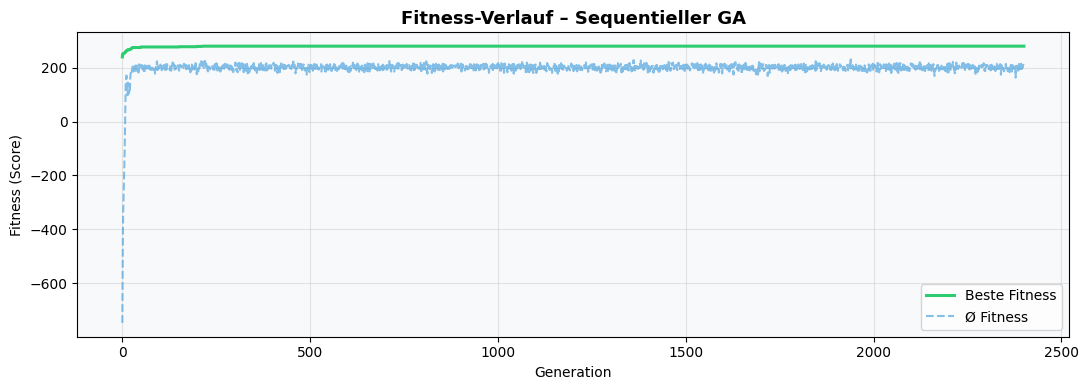

✅ Plot 1: Fitness-Verlauf


In [16]:
# ── Plot 1: Fitness-Verlauf ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(result_seq["history_best"], color="#2ecc71", lw=2.2, label="Beste Fitness")
ax.plot(result_seq["history_avg"],  color="#3498db", lw=1.5, alpha=0.6,
        linestyle="--", label="Ø Fitness")
ax.set_title("Fitness-Verlauf – Sequentieller GA", fontsize=13, fontweight="bold")
ax.set_xlabel("Generation"); ax.set_ylabel("Fitness (Score)")
ax.legend(); ax.grid(True, alpha=0.3); ax.set_facecolor("#f8f9fa")
plt.tight_layout()
plt.savefig("fitness_history.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Plot 1: Fitness-Verlauf")


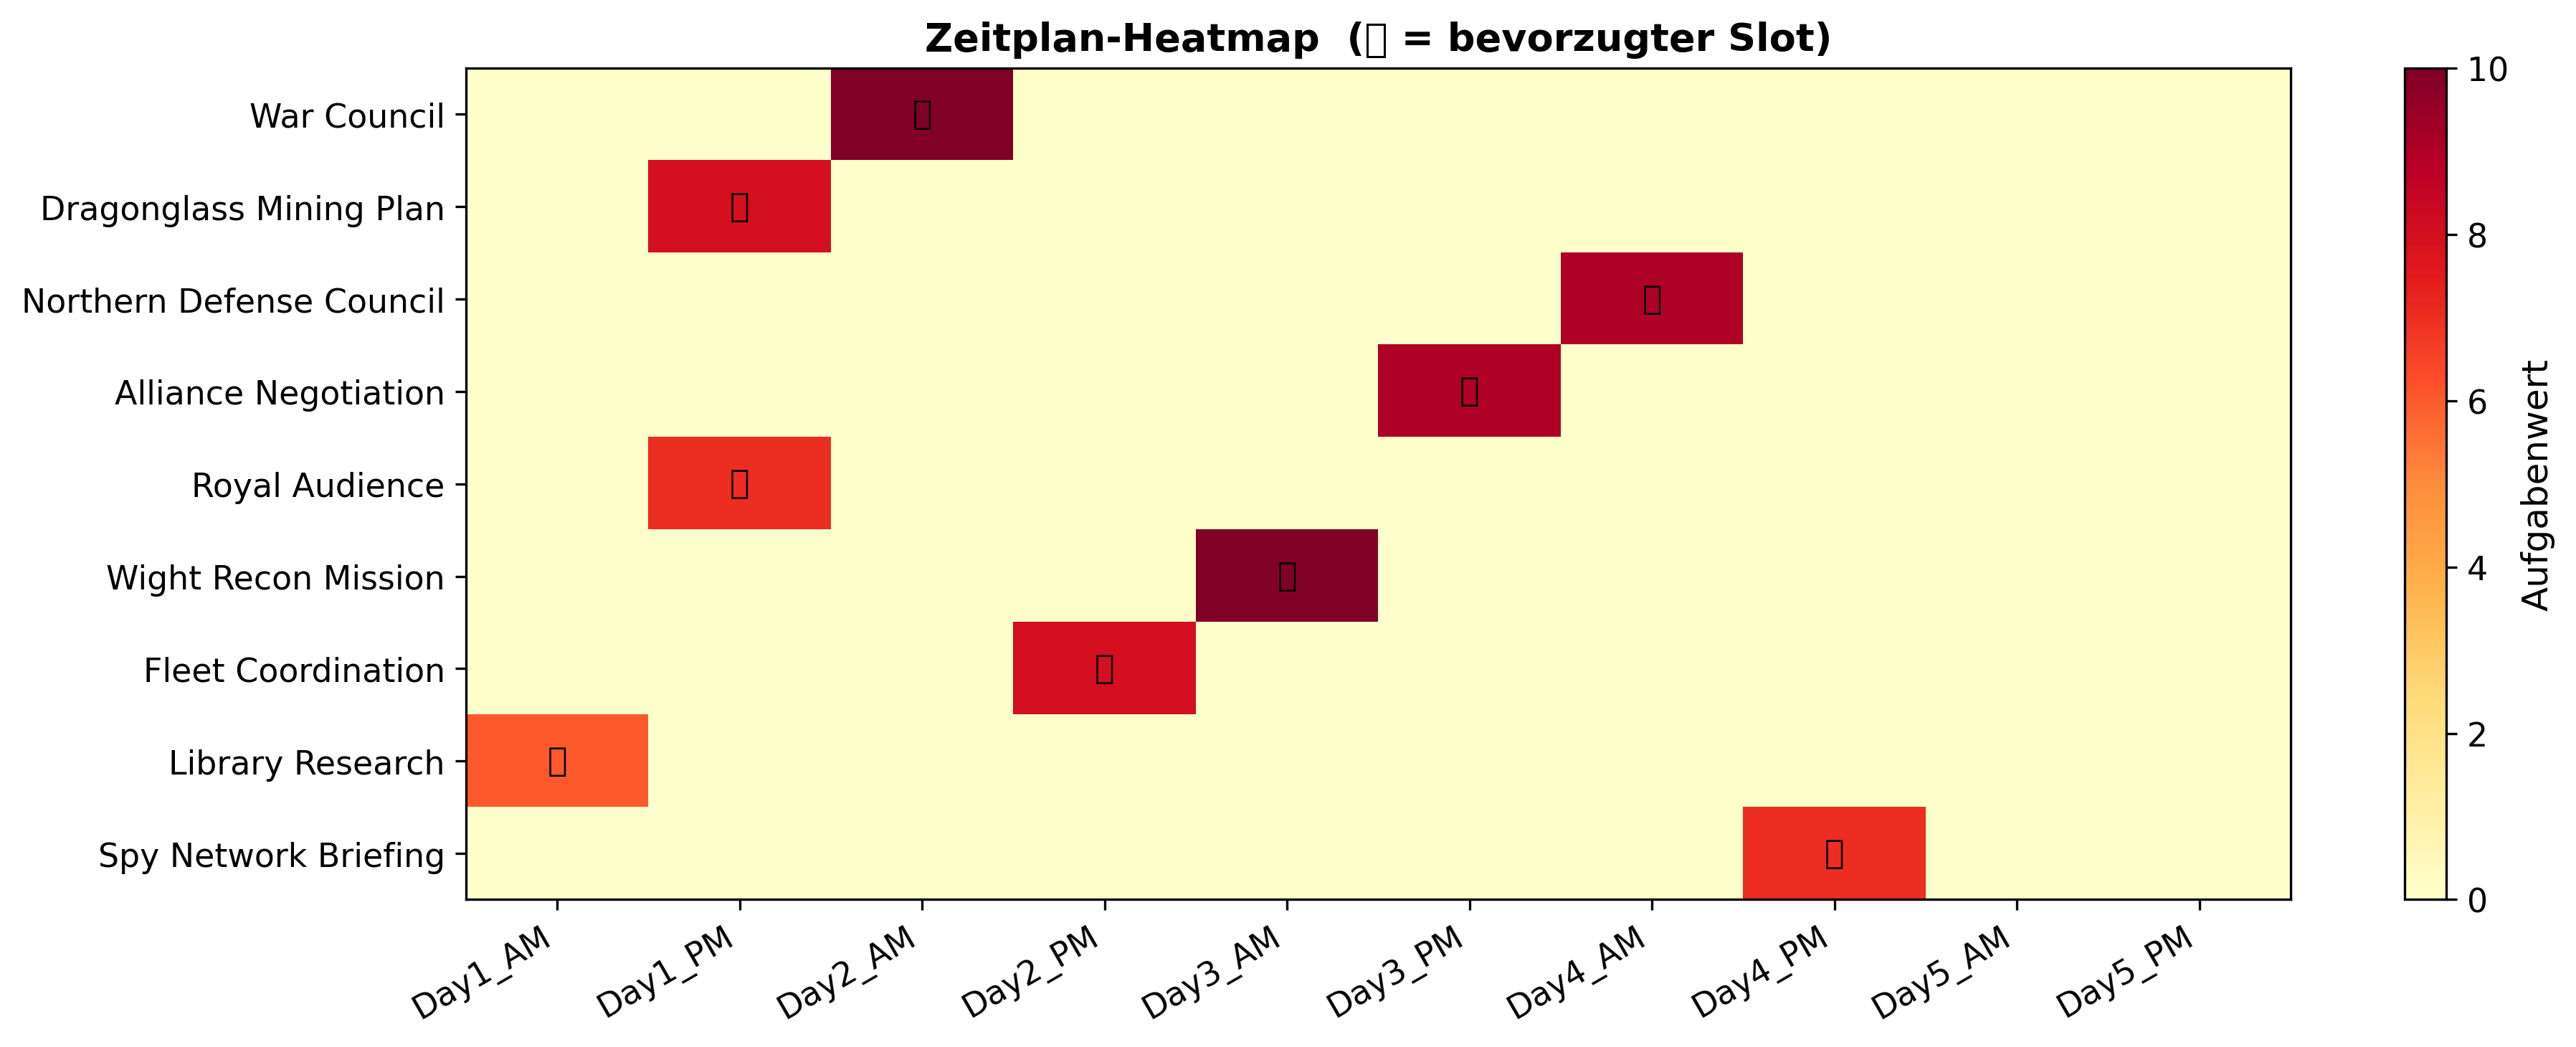

✅ Plot 2: Zeitplan-Heatmap


In [44]:
# ── Plot 2: Zeitplan-Heatmap ──────────────────────────────────────────────
sched = result_par["best_schedule"]
task_names_list = list(TASKS.keys())
n_tasks = len(task_names_list)

# Matrix: task × timeslot (1 wenn eingeplant)
heat = np.zeros((n_tasks, len(TIMESLOTS)))
pref_mask = np.zeros((n_tasks, len(TIMESLOTS)))
ts_idx = {ts: i for i, ts in enumerate(TIMESLOTS)}

for ti, tname in enumerate(task_names_list):
    slot = sched[tname]
    col  = ts_idx.get(slot["timeslot"], -1)
    if col >= 0:
        heat[ti, col] = TASKS[tname].value
        if slot["timeslot"] in TASKS[tname].preferred_timeslots:
            pref_mask[ti, col] = 1

fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(heat, cmap="YlOrRd", aspect="auto", vmin=0)
plt.colorbar(im, ax=ax, label="Aufgabenwert")

# Stern für bevorzugte Slots
for ti in range(n_tasks):
    for si in range(len(TIMESLOTS)):
        if pref_mask[ti, si]:
            ax.text(si, ti, "⭐", ha="center", va="center", fontsize=11)
        elif heat[ti, si] > 0:
            ax.text(si, ti, f"{int(heat[ti,si])}", ha="center", va="center",
                    fontsize=9, fontweight="bold", color="white")

ax.set_xticks(range(len(TIMESLOTS))); ax.set_xticklabels(TIMESLOTS, rotation=30, ha="right")
ax.set_yticks(range(n_tasks)); ax.set_yticklabels(task_names_list)
ax.set_title("Zeitplan-Heatmap  (⭐ = bevorzugter Slot)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("schedule_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Plot 2: Zeitplan-Heatmap")


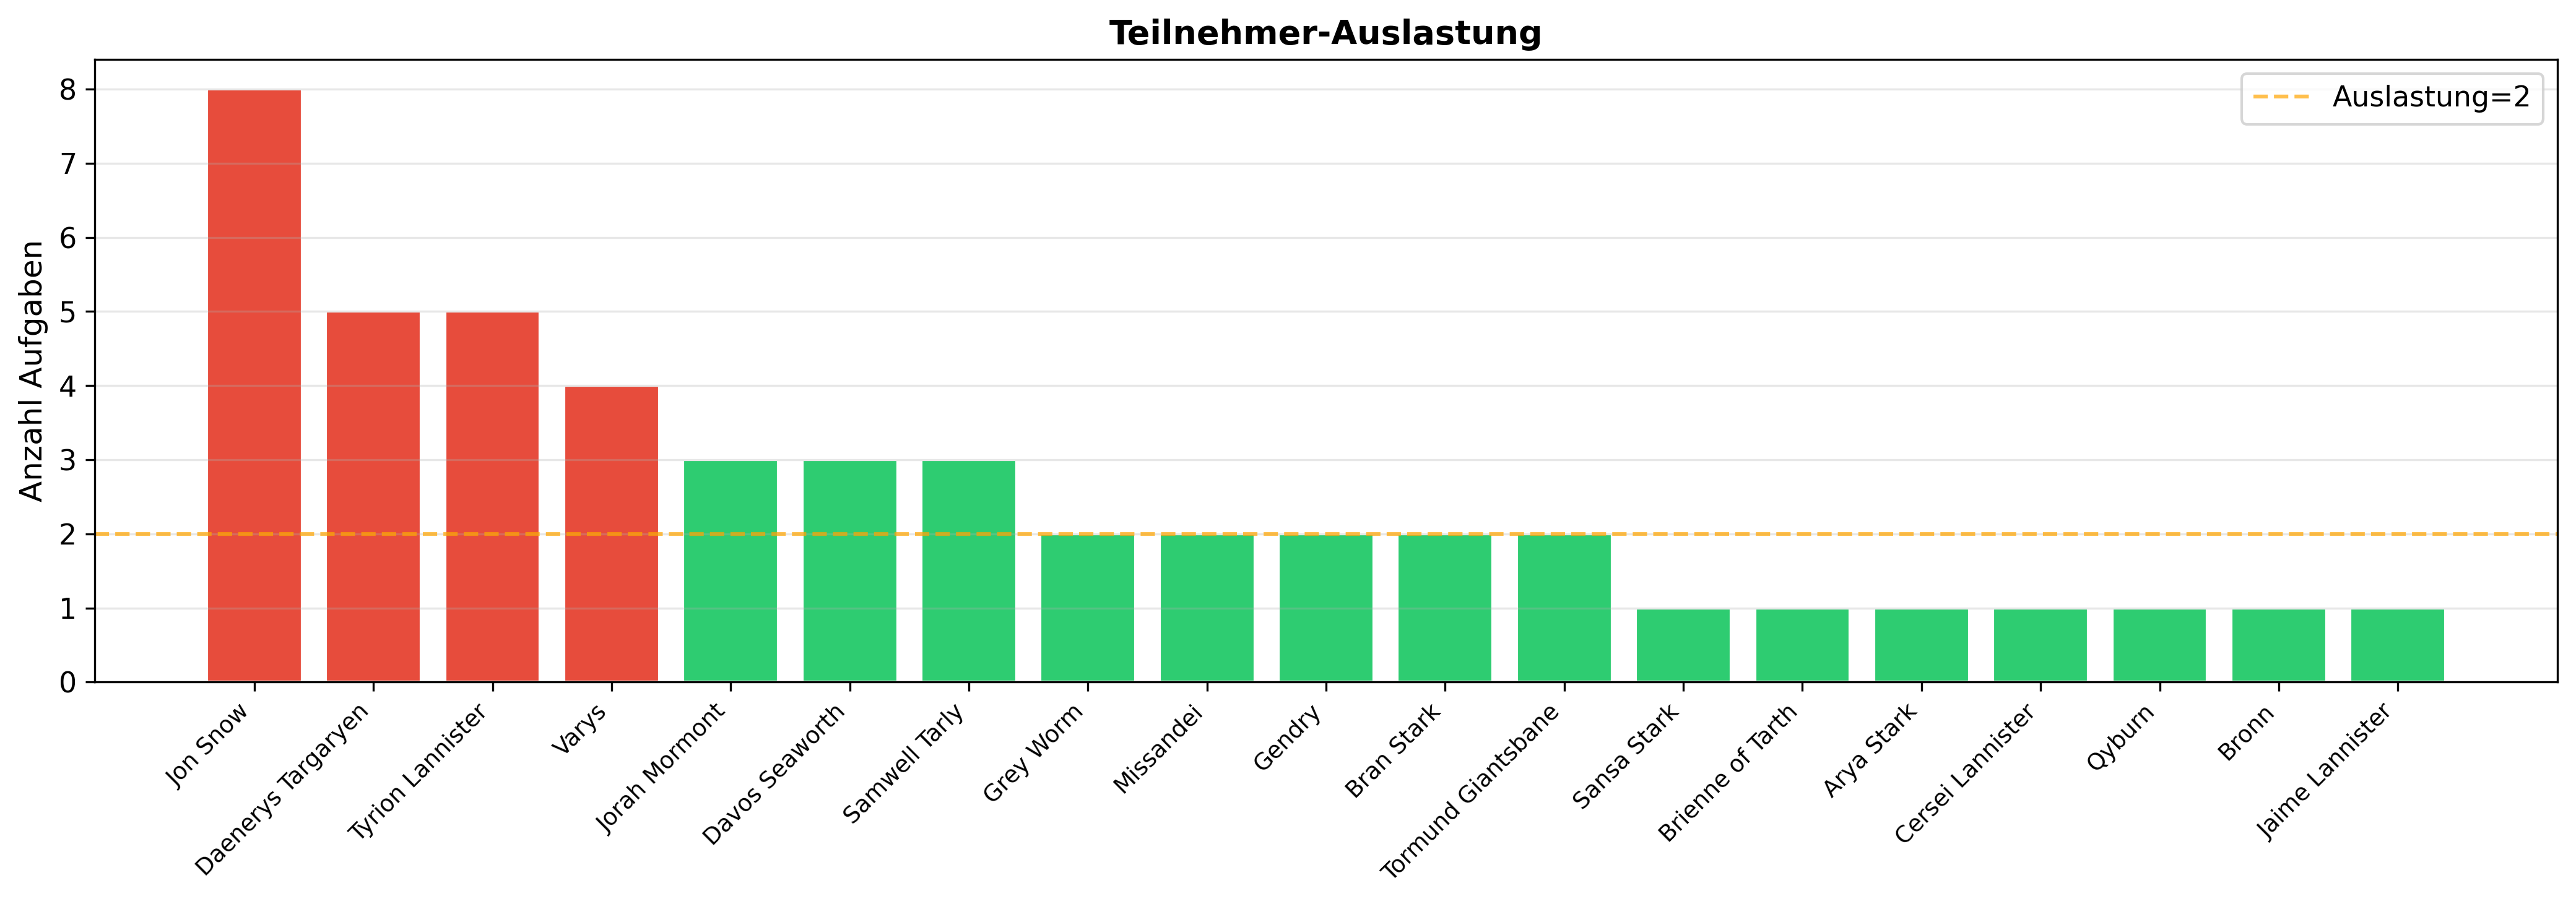

✅ Plot 3: Teilnehmer-Auslastung


In [45]:
# ── Plot 3: Teilnehmer-Auslastung ─────────────────────────────────────────
from collections import Counter

char_load = Counter()
for slot in sched.values():
    for p in slot["attendees"]:
        char_load[p] += 1

# Nur Charaktere mit mind. einer Aufgabe
names_sorted = [n for n, _ in char_load.most_common()]
counts       = [char_load[n] for n in names_sorted]
colors_bar   = ["#e74c3c" if char_load[n] > 3 else "#2ecc71" for n in names_sorted]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(names_sorted, counts, color=colors_bar, edgecolor="white")
ax.axhline(y=2, color="orange", linestyle="--", alpha=0.7, label="Auslastung=2")
ax.set_xticklabels(names_sorted, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Anzahl Aufgaben"); ax.set_title("Teilnehmer-Auslastung", fontsize=13, fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("character_load.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Plot 3: Teilnehmer-Auslastung")


In [19]:
import matplotlib.pyplot as plt

from IPython.display import display, clear_output

class IslandVisualizer:
    def __init__(self, tasks, timeslots):

        self.tasks = [t["name"] for t in tasks]

        # original values for lookup
        self.timeslots = timeslots

        # shortened values only for display
        self.timeslots_display = [
            t.replace("Day", "D")
            .replace("_", " ")
            for t in timeslots
        ]

        self.fig, self.axes = plt.subplots(
            2, 2,
            figsize=(40, 20)
        )

        self.axes = self.axes.flatten()

        plt.subplots_adjust(
            left=0.03,
            right=0.98,
            top=0.90,
            bottom=0.05,
            wspace=0.4,
            hspace=0.5
        )
    def schedule_to_table(self, schedule):

        table = [
            ["" for _ in self.timeslots]
            for _ in self.tasks
        ]

        task_index = {
            t: i for i, t in enumerate(self.tasks)
        }

        # IMPORTANT: use original timeslots here
        slot_index = {
            t: i for i, t in enumerate(self.timeslots)
        }

        for task_name, assignment in schedule.items():

            r = task_index[task_name]

            c = slot_index[
                assignment["timeslot"]
            ]

            txt = assignment["location"]

            if assignment["attendees"]:

                names = [
                    p.split()[0]
                    for p in assignment["attendees"][:2]
                ]

                if len(assignment["attendees"]) > 2:
                    names.append("+")

                txt += "\n" + ",".join(names)

            table[r][c] = txt

        return table

    def update(self, schedules, fitnesses, generation):

        clear_output(wait=True)

        for island in range(4):

            ax = self.axes[island]
            ax.clear()

            table_data = self.schedule_to_table(
                schedules[island]
            )

            table = ax.table(
                cellText=table_data,
                rowLabels=self.tasks,
                colLabels=self.timeslots_display,
                cellLoc="center",
                loc="center",
                colWidths=[0.12] * len(self.timeslots_display)
            )


            # readable font
            table.auto_set_font_size(False)
            table.set_fontsize(16)

            # increase cell height only
            table.scale(
                1,
                4
            )


            # wrap text
            for cell in table.get_celld().values():
                cell.get_text().set_wrap(True)


            ax.set_title(
                f"Island {island+1}\n"
                f"Fitness: {fitnesses[island]:.1f}",
                fontsize=14,
                pad=20
            )

            ax.axis("off")


        self.fig.suptitle(
            f"Generation {generation}",
            fontsize=24
        )

        display(self.fig)

        plt.close(self.fig)

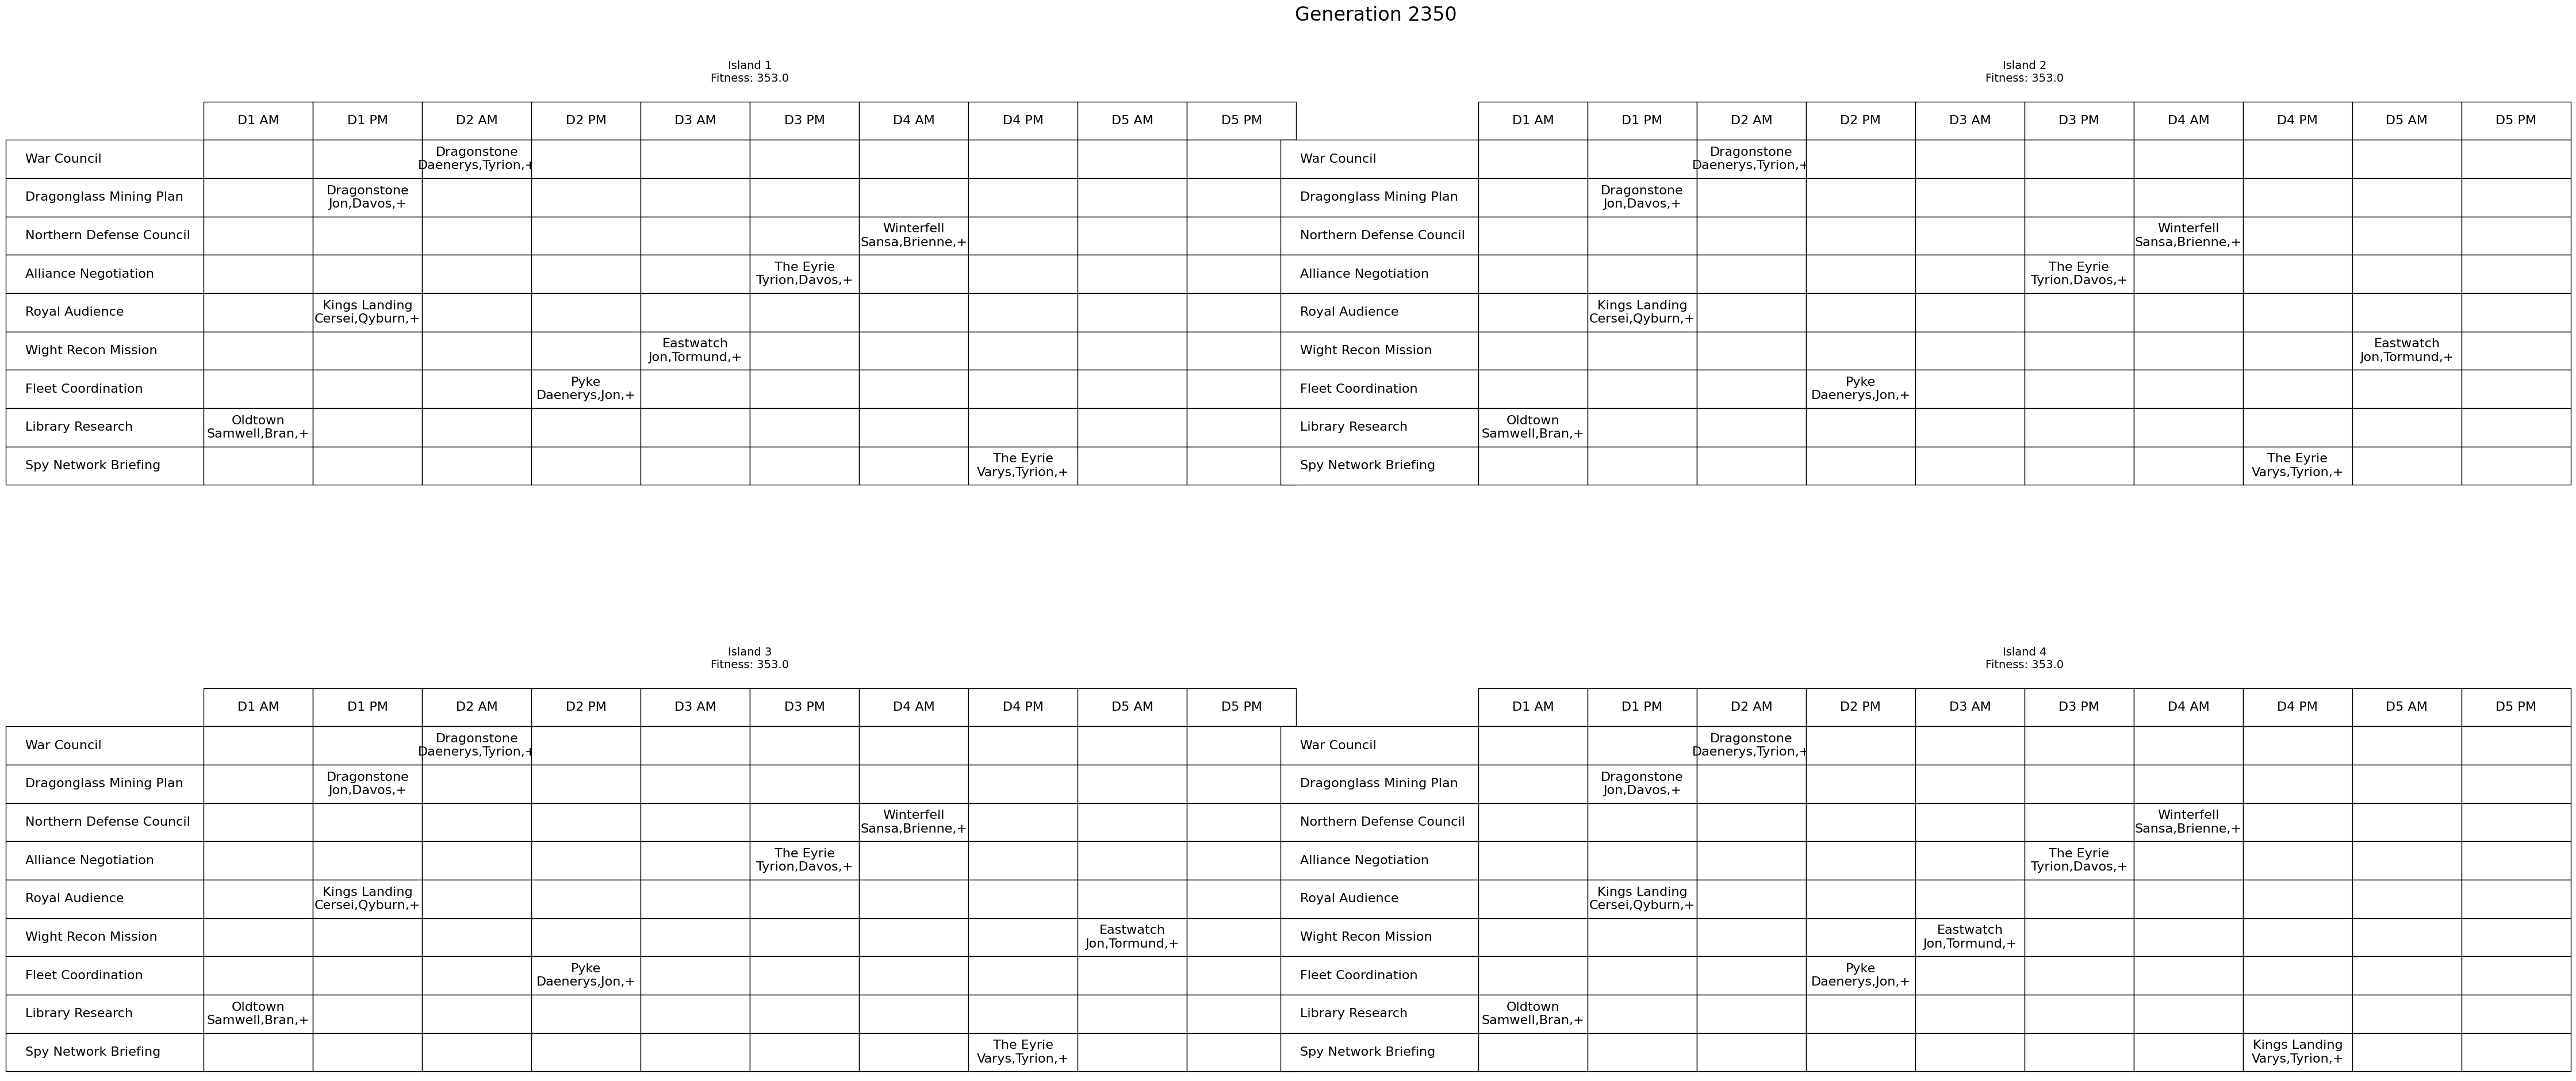

[[{'War Council': {'timeslot': 'Day2_AM', 'location': 'Dragonstone', 'attendees': ['Daenerys Targaryen', 'Tyrion Lannister', 'Grey Worm', 'Jorah Mormont', 'Jon Snow', 'Varys', 'Missandei']}, 'Dragonglass Mining Plan': {'timeslot': 'Day1_PM', 'location': 'Dragonstone', 'attendees': ['Jon Snow', 'Davos Seaworth', 'Gendry', 'Tyrion Lannister', 'Daenerys Targaryen']}, 'Northern Defense Council': {'timeslot': 'Day4_AM', 'location': 'Winterfell', 'attendees': ['Sansa Stark', 'Brienne of Tarth', 'Jon Snow', 'Arya Stark', 'Samwell Tarly', 'Bran Stark', 'Tormund Giantsbane']}, 'Alliance Negotiation': {'timeslot': 'Day3_PM', 'location': 'The Eyrie', 'attendees': ['Tyrion Lannister', 'Davos Seaworth', 'Jaime Lannister', 'Jon Snow', 'Varys', 'Daenerys Targaryen']}, 'Royal Audience': {'timeslot': 'Day1_PM', 'location': 'Kings Landing', 'attendees': ['Cersei Lannister', 'Qyburn', 'Bronn', 'Jaime Lannister']}, 'Wight Recon Mission': {'timeslot': 'Day3_AM', 'location': 'Eastwatch', 'attendees': ['Jon 

In [ ]:
# Slide
result_par_vis = run_parallel_ga_vis(
    n_islands=4,
    pop_per_island=80,
    n_generations_total=2400,
    migration_interval=400,
    mutation_rate=0.35,
    base_seed=RANDOM_SEED
)


---
## 9. Parameterstudie – Einfluss von Populationsgröße & Mutationsrate


2026-07-30 23:32:51,096 - INFO - Starting parallel GA with 4 islands, 400 generations per round
2026-07-30 23:32:51,228 - INFO - Round 1/4 starting


📊 Parameterstudie: Populationsgröße (1600 Generationen)
-------------------------------------------------------


2026-07-30 23:32:59,084 - INFO - New global best found: 350.00
2026-07-30 23:32:59,085 - INFO - Round 2/4 starting


  [Runde 1/4] Beste Fitness: 350.0 | Verletzungen: 0


2026-07-30 23:33:07,918 - INFO - New global best found: 351.00
2026-07-30 23:33:07,920 - INFO - New global best found: 352.00
2026-07-30 23:33:07,921 - INFO - Round 3/4 starting


...

  [Runde 2/4] Beste Fitness: 350.0 | Verletzungen: 0


2026-07-30 23:41:31,656 - INFO - New global best found: 352.00
2026-07-30 23:41:31,657 - INFO - Round 4/4 starting


  [Runde 3/4] Beste Fitness: 352.0 | Verletzungen: 0


2026-07-30 23:42:45,649 - INFO - New global best found: 353.00
2026-07-30 23:42:45,663 - INFO - Parallel GA finished in 294.66 seconds
2026-07-30 23:42:45,698 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-30 23:42:45,701 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


  [Runde 4/4] Beste Fitness: 353.0 | Verletzungen: 0
  Pop= 250 | Fitness:   353.0 | Verletzungen: 0 | Zeit: 294.66s


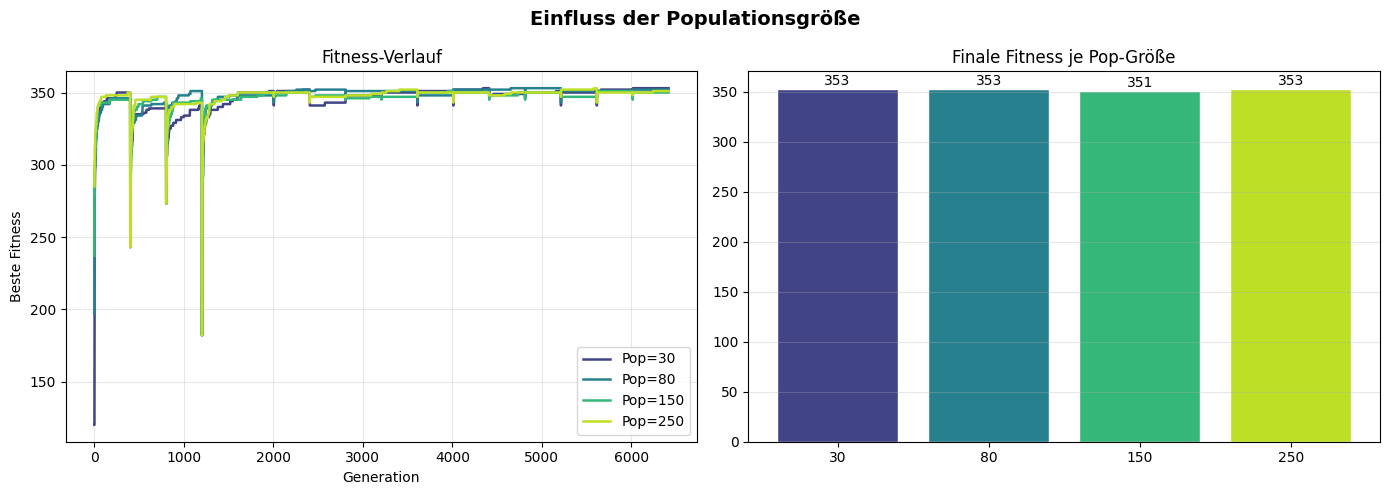

✅ Parameterstudie Populationsgröße abgeschlossen


In [22]:
# ── Populationsgrößen ───────────────────────────────────────────────────── # Slide
pop_sizes    = [30, 80, 150, 250]
results_pop  = {}
print("📊 Parameterstudie: Populationsgröße (1600 Generationen)")
print("-" * 55)
for ps in pop_sizes:
    #r = run_ga(TASKS, CHARACTERS, SCORING, pop_size=ps, n_generations=200, verbose=False, seed=RANDOM_SEED)
    
    r = run_parallel_ga(
    n_islands=4, pop_per_island=ps,
    n_generations_total=1600, migration_interval=400,
    mutation_rate=0.35, base_seed=RANDOM_SEED,
    )
    viol = sum(count_violations(r["best_schedule"], TASKS, CHARACTERS).values())
    results_pop[ps] = r
    print(f"  Pop={ps:4d} | Fitness: {r['best_fitness']:7.1f} | "
          f"Verletzungen: {viol} | Zeit: {r['elapsed']:.2f}s")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Einfluss der Populationsgröße", fontsize=14, fontweight="bold")
colors_p = plt.cm.viridis(np.linspace(0.2, 0.9, len(pop_sizes)))

for (ps, r), c in zip(results_pop.items(), colors_p):
    axes[0].plot(r["history_best"], label=f"Pop={ps}", color=c, lw=1.8)
axes[0].set_title("Fitness-Verlauf"); axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Beste Fitness"); axes[0].legend(); axes[0].grid(alpha=0.3)

finals = [results_pop[ps]["best_fitness"] for ps in pop_sizes]
bars   = axes[1].bar([str(ps) for ps in pop_sizes], finals, color=colors_p, edgecolor="white")
for b, v in zip(bars, finals):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.5, f"{v:.0f}",
                 ha="center", va="bottom", fontsize=10)
axes[1].set_title("Finale Fitness je Pop-Größe"); axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("param_popsize.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Parameterstudie Populationsgröße abgeschlossen")


2026-07-30 23:42:46,622 - INFO - Starting parallel GA with 4 islands, 400 generations per round
2026-07-30 23:42:46,746 - INFO - Round 1/4 starting



📊 Parameterstudie: Mutationsrate (1600 Generationen, Pop=80)
-------------------------------------------------------


2026-07-30 23:43:09,425 - INFO - New global best found: 348.00
2026-07-30 23:43:09,426 - INFO - New global best found: 350.00
2026-07-30 23:43:09,426 - INFO - Round 2/4 starting


  [Runde 1/4] Beste Fitness: 350.0 | Verletzungen: 0


2026-07-30 23:43:32,174 - INFO - New global best found: 351.00
2026-07-30 23:43:32,175 - INFO - New global best found: 353.00
2026-07-30 23:43:32,177 - INFO - Round 3/4 starting


...

  [Runde 2/4] Beste Fitness: 351.0 | Verletzungen: 0


2026-07-30 23:48:34,805 - INFO - Round 4/4 starting


  [Runde 3/4] Beste Fitness: 351.0 | Verletzungen: 0


2026-07-30 23:48:57,956 - INFO - New global best found: 352.00
2026-07-30 23:48:57,971 - INFO - Parallel GA finished in 93.65 seconds


  [Runde 4/4] Beste Fitness: 352.0 | Verletzungen: 0
  MutRate=0.33 | Fitness:   352.0 | Verletzungen: 0


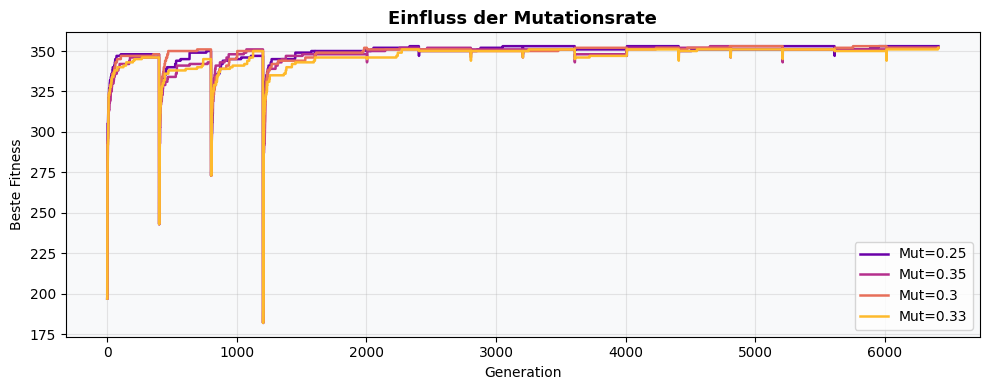

✅ Parameterstudie Mutationsrate abgeschlossen


In [23]:
# ── Mutationsraten ────────────────────────────────────────────────────────
mut_rates   = [0.25, 0.35, 0.30, 0.33]
results_mut = {}
print("\n📊 Parameterstudie: Mutationsrate (1600 Generationen, Pop=80)")
print("-" * 55)
for mr in mut_rates:
    r = run_parallel_ga(
        n_islands=4, pop_per_island=80,
        n_generations_total=1600, migration_interval=400,
        mutation_rate=mr, base_seed=RANDOM_SEED,
        )
    viol = sum(count_violations(r["best_schedule"], TASKS, CHARACTERS).values())
    results_mut[mr] = r
    print(f"  MutRate={mr:.2f} | Fitness: {r['best_fitness']:7.1f} | Verletzungen: {viol}")

fig, ax = plt.subplots(figsize=(10, 4))
colors_m = plt.cm.plasma(np.linspace(0.2, 0.85, len(mut_rates)))
for (mr, r), c in zip(results_mut.items(), colors_m):
    ax.plot(r["history_best"], label=f"Mut={mr}", color=c, lw=1.8)
ax.set_title("Einfluss der Mutationsrate", fontsize=13, fontweight="bold")
ax.set_xlabel("Generation"); ax.set_ylabel("Beste Fitness")
ax.legend(); ax.grid(alpha=0.3); ax.set_facecolor("#f8f9fa")
plt.tight_layout()
plt.savefig("param_mutation.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Parameterstudie Mutationsrate abgeschlossen")


In [24]:
import time
import pandas as pd
# Mutation Strategy: Biased vs. Non-biased
# --------------------------------------------------
# Benchmark settings
# --------------------------------------------------
N_RUNS = 10
TARGET_FITNESS = 353
BASE_SEED = RANDOM_SEED

results_mut = []

print(f"Running {N_RUNS} repetitions for each algorithm...\n")


# --------------------------------------------------
# 
# --------------------------------------------------
print("=== Testing run_parallel_non_biased_mutation ===")

for i in range(N_RUNS):
    seed = BASE_SEED + i

    start = time.perf_counter()

    result = run_parallel_ga_non_biased_mutation(
        n_islands=6,
        pop_per_island=80,
        n_generations_total=2400,
        migration_interval=400,
        mutation_rate=0.35,
        base_seed=seed,
        mutation_ratio=2
        
    )

    elapsed = time.perf_counter() - start

    fitness = result["best_fitness"]

    results_mut.append({
        "algorithm": "Non biased mutation",
        "run": i + 1,
        "seed": seed,
        "fitness": fitness,
        "success": fitness >= TARGET_FITNESS,
        "time_seconds": elapsed,
        "target_found_generation": result["target_found_generation"],
        "target_found_time": result["target_found_time"]
    })

    print(
        f"Run {i+1:2d}: "
        f"Fitness={fitness:6.2f} | "
        f"Time={elapsed:7.2f}s | "
        f"{'SUCCESS' if fitness >= TARGET_FITNESS else 'FAIL'}"
    )

# --------------------------------------------------
# biased mutation
# --------------------------------------------------
print("\n=== Testing run_parallel_ga ===")

for i in range(N_RUNS):
    seed = BASE_SEED + i

    start = time.perf_counter()

    result = run_parallel_ga(
        n_islands=6,
        pop_per_island=80,
        n_generations_total=600,
        migration_interval=100,
        mutation_rate=0.35,
        base_seed=seed,
        mutation_ratio=2,
        target_generation_wanted=True
    )

    elapsed = time.perf_counter() - start

    fitness = result["best_fitness"]
    results_mut.append({
        "algorithm": "biased mutation",
        "run": i + 1,
        "seed": seed,
        "fitness": fitness,
        "success": fitness >= TARGET_FITNESS,
        "time_seconds": elapsed,
        "target_found_generation": result["target_found_generation"],
        "target_found_time": result["target_found_time"]

    })

    print(
        f"Run {i+1:2d}: "
        f"Fitness={fitness:6.2f} | "
        f"Time={elapsed:7.2f}s | "
        f"{'SUCCESS' if fitness >= TARGET_FITNESS else 'FAIL'}"
    )


# --------------------------------------------------
# Results
# --------------------------------------------------
df_results_mut = pd.DataFrame(results_mut)
summary = (
    df_results_mut
    .groupby("algorithm")
    .agg(
        Runs=("fitness", "count"),
        Successes=("success", "sum"),
        SuccessRate=("success", "mean"),
        MeanFitness=("fitness", "mean"),
        BestFitness=("fitness", "max"),

        MeanGenerationsTo353=("target_found_generation", "mean"),
        StdGenerationsTo353=("target_found_generation", "std"),

        MeanTimeSeconds=("target_found_time", "mean"),
        StdTimeSeconds=("target_found_time", "std"),
        FastestSeconds=("target_found_time", "min"),
        SlowestSeconds=("target_found_time", "max"),
    )
)

summary["SuccessRate"] *= 100

print("\n==============================")
print("SUMMARY")
print("==============================")

display(
    summary.round({
        "SuccessRate": 1,
        "MeanFitness": 2,
        "BestFitness": 2,
        "MeanGenerationsTo353": 1,
        "StdGenerationsTo353": 1,
        "MeanTimeSeconds": 2,
        "StdTimeSeconds": 2,
        "FastestSeconds": 2,
        "SlowestSeconds": 2,
    })
)
#todo
display(df_results_mut)

2026-07-31 20:41:11,405 - INFO - Starting parallel GA with 6 islands, 400 generations per round


Running 10 repetitions for each algorithm...

=== Testing run_parallel_non_biased_mutation ===


2026-07-31 20:41:11,769 - INFO - Round 1/6 starting
2026-07-31 20:41:43,477 - INFO - New global best found: 345.00
2026-07-31 20:41:43,478 - INFO - New global best found: 347.00
2026-07-31 20:41:43,480 - INFO - New global best found: 349.00
2026-07-31 20:41:43,482 - INFO - Round 2/6 starting


  [Runde 1/6] Beste Fitness: 349.0 | Verletzungen: 0


2026-07-31 20:42:17,770 - INFO - New global best found: 351.00
2026-07-31 20:42:17,772 - INFO - Round 3/6 starting


...

  [Runde 5/6] Beste Fitness: 353.0 | Verletzungen: 0


2026-07-31 21:22:29,690 - INFO - Parallel GA finished in 61.91 seconds


  [Runde 6/6] Beste Fitness: 353.0 | Verletzungen: 0
Run 10: Fitness=353.00 | Time=  61.92s | SUCCESS

SUMMARY


,Runs,Successes,SuccessRate,MeanFitness,BestFitness,MeanGenerationsTo353,StdGenerationsTo353,MeanTimeSeconds,StdTimeSeconds,FastestSeconds,SlowestSeconds
algorithm,,,,,,,,,,,
Non biased mutation,10,10,100.0,353.0,353.0,924.7,446.3,72.37,36.54,28.22,135.77
biased mutation,10,10,100.0,353.0,353.0,183.0,37.2,18.96,4.47,13.60,25.61


,algorithm,run,seed,fitness,success,time_seconds,target_found_generation,target_found_time
0,Non biased mutation,1,43,353.0,True,194.550903,1621,135.770142
1,Non biased mutation,2,44,353.0,True,179.269332,1039,77.079482
2,Non biased mutation,3,45,353.0,True,181.921909,387,28.216282
3,Non biased mutation,4,46,353.0,True,185.738323,636,49.244076
4,Non biased mutation,5,47,353.0,True,190.870845,1181,92.790581
5,Non biased mutation,6,48,353.0,True,194.513284,1475,118.163527
6,Non biased mutation,7,49,353.0,True,192.010205,841,68.322845
7,Non biased mutation,8,50,353.0,True,204.715856,387,31.419268
8,Non biased mutation,9,51,353.0,True,176.818494,491,38.539846
9,Non biased mutation,10,52,353.0,True,171.050827,1189,84.189850


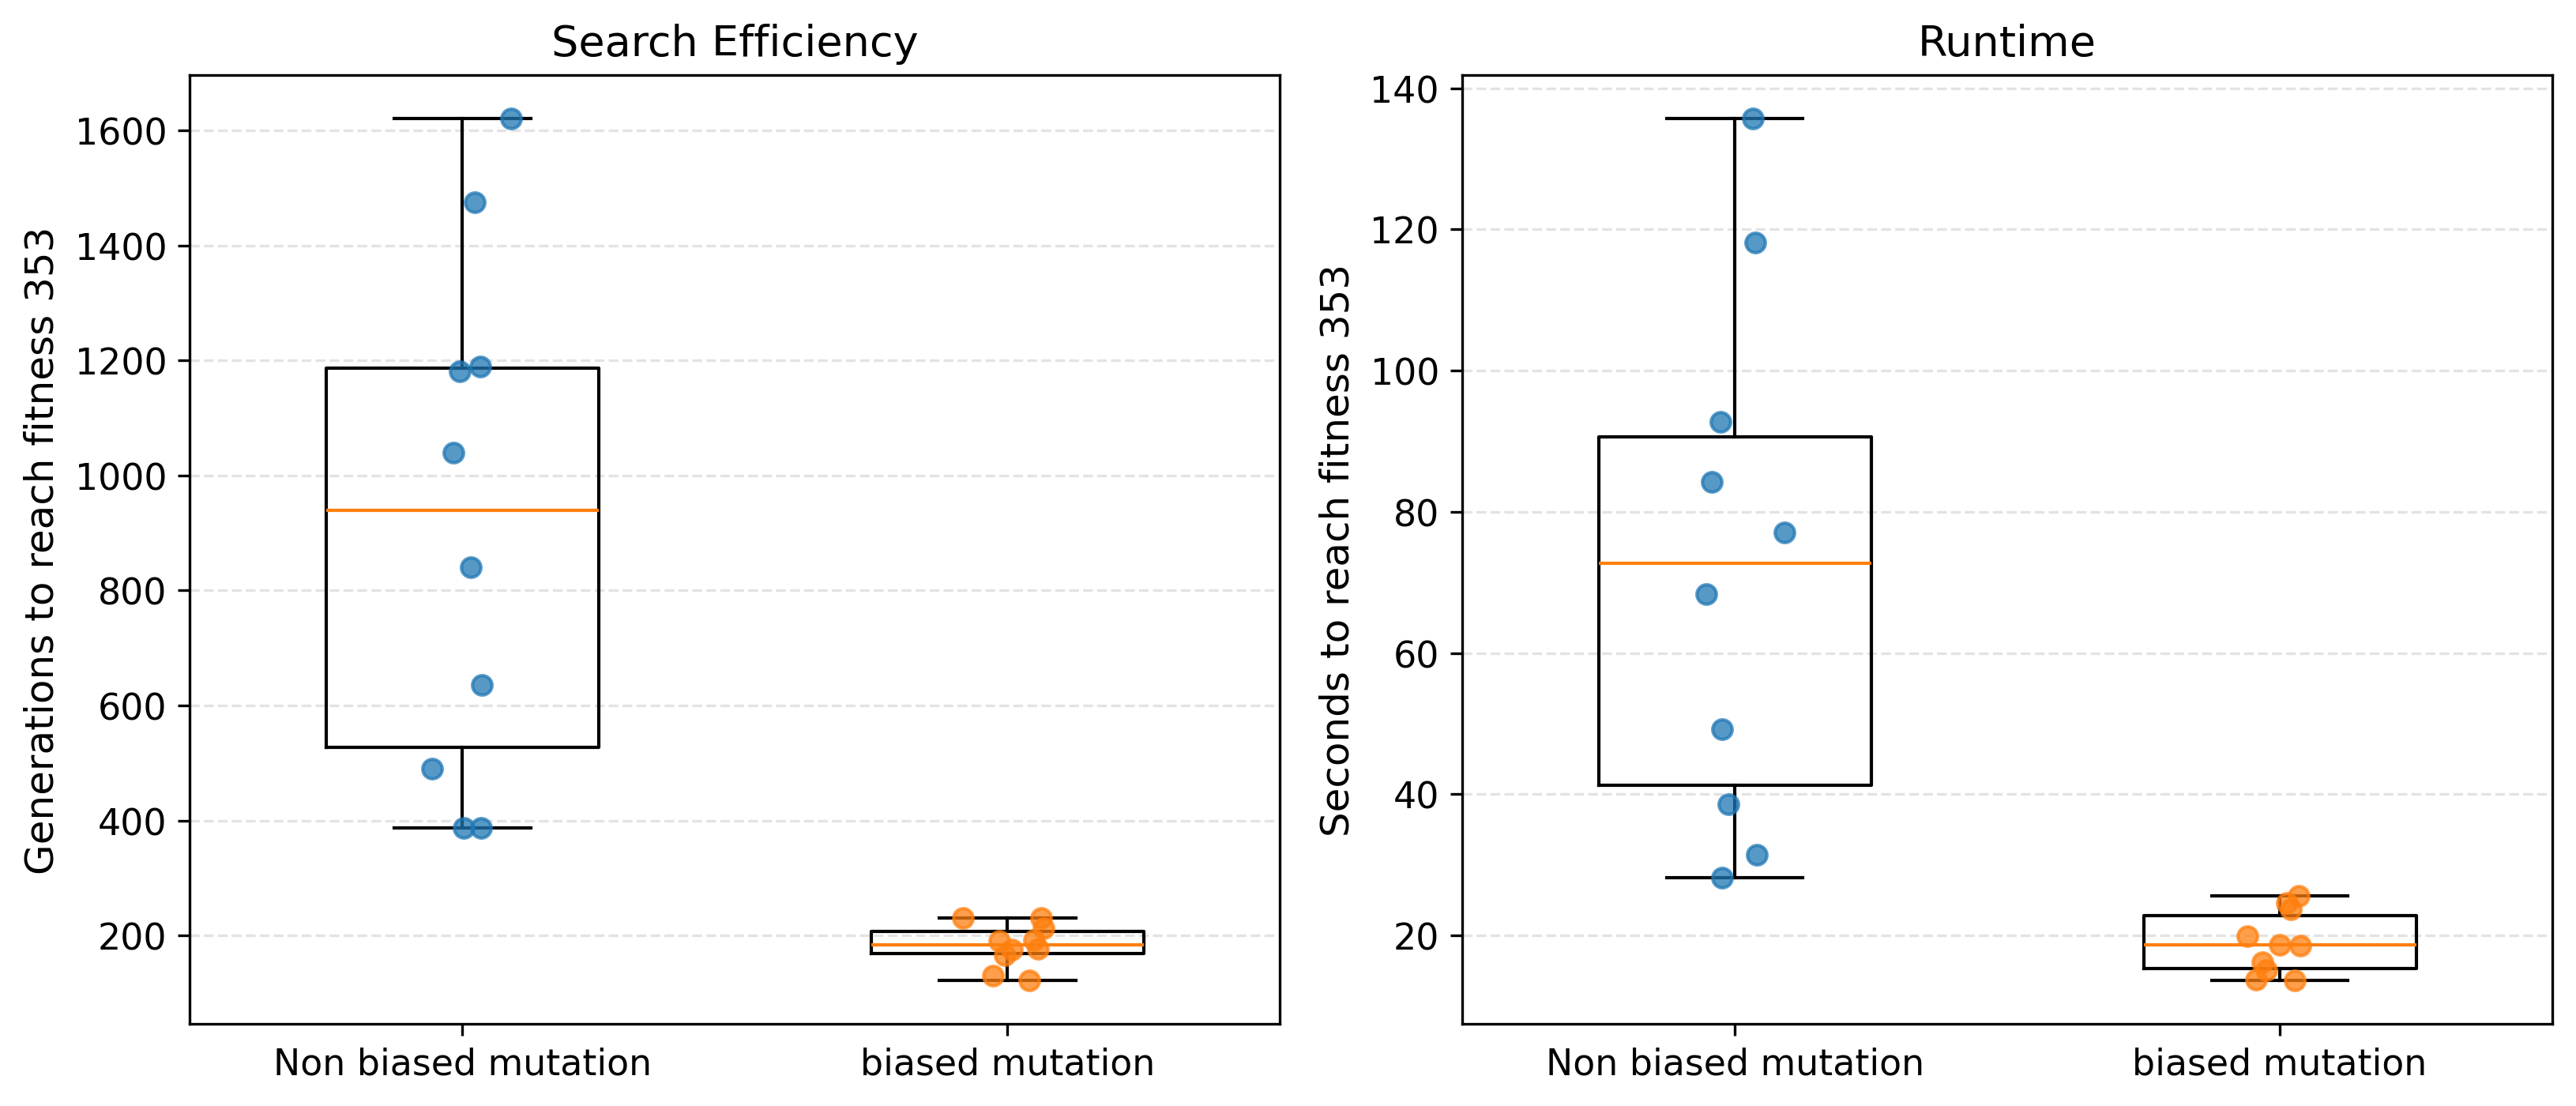

In [25]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 300,
    "savefig.dpi": 300,
})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

algorithms = list(df_results_mut["algorithm"].dropna().unique())

# ----------------------------------------------------
# Left: Generations to target
# ----------------------------------------------------
gen_data = [
    df_results_mut.loc[
        df_results_mut["algorithm"] == alg,
        "target_found_generation"
    ].dropna()
    for alg in algorithms
]

axes[0].boxplot(
    gen_data,
    labels=algorithms,
    widths=0.5,
    showfliers=False,
)

# overlay individual runs
for i, values in enumerate(gen_data, start=1):
    jitter = np.random.normal(i, 0.04, len(values))
    axes[0].scatter(
        jitter,
        values,
        s=35,
        alpha=0.75,
        zorder=3,
    )

axes[0].set_ylabel("Generations to reach fitness 353")
axes[0].set_title("Search Efficiency")
axes[0].grid(axis="y", linestyle="--", alpha=0.35)

# ----------------------------------------------------
# Right: Time to target
# ----------------------------------------------------
time_data = [
    df_results_mut.loc[
        df_results_mut["algorithm"] == alg,
        "target_found_time"
    ].dropna()
    for alg in algorithms
]

axes[1].boxplot(
    time_data,
    labels=algorithms,
    widths=0.5,
    showfliers=False,
)

for i, values in enumerate(time_data, start=1):
    jitter = np.random.normal(i, 0.04, len(values))
    axes[1].scatter(
        jitter,
        values,
        s=35,
        alpha=0.75,
        zorder=3,
    )

axes[1].set_ylabel("Seconds to reach fitness 353")
axes[1].set_title("Runtime")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

In [27]:
print(algorithms)

for alg, values in zip(algorithms, gen_data):
    print(
        alg,
        values.quantile([0.25, 0.5, 0.75]).to_dict()
    )

['Non biased mutation', 'biased mutation']
Non biased mutation {0.25: 1301.0, 0.5: 1475.0, 0.75: 1625.0}
biased mutation {0.25: 303.0, 0.5: 303.0, 0.75: 641.25}


In [17]:
import numpy as np
import pandas as pd
#Parameter Study: Mutation Ratio
mut_ratios = [1,2,3,5,10,25,35]
n_runs = 5
target_fitness = 353

results_mut_rat = {}
records = []

print("\n📊 Mutation ratio study (5 runs each)")
print("-" * 80)

for mr in mut_ratios:
    results_mut_rat[mr] = []

    for run in range(n_runs):

        print(f"\nRunning mutation_ratio={mr}, run={run+1}/{n_runs}")

        r = run_parallel_ga(
            n_islands=4,
            pop_per_island=80,
            n_generations_total=2400,
            migration_interval=400,
            mutation_rate=0.35,
            base_seed=RANDOM_SEED + run,
            mutation_ratio=mr,
            target_generation_wanted=True
        )

        gen = r["target_found_generation"]
        time_to_353 = r["target_found_time"]

        viol = sum(
            count_violations(
                r["best_schedule"],
                TASKS,
                CHARACTERS
            ).values()
        )

        results_mut_rat[mr].append(r)

        records.append({
            "mutation_ratio": mr,
            "run": run + 1,
            "best_fitness": r["best_fitness"],

            "generation_353": gen,
            "time_to_353_seconds": time_to_353,

            "found": gen is not None,
            "runtime_seconds": r["elapsed"],
            "violations": viol
        })

        
        if gen is None or np.isnan(gen):
            print(
                f"  Fitness={r['best_fitness']:.1f} | "
                f"353 not found | "
                f"time={r['elapsed']:.1f}s"
            )
        else:
            print(
                f"  Fitness={r['best_fitness']:.1f} | "
                f"353 found at generation {int(gen)} | "
                f"time={r['elapsed']:.1f}s"
            )


df_mut_rat = pd.DataFrame(records)

print("\n===== Summary =====")

summary = (
    df_mut_rat
    .groupby("mutation_ratio")
    .agg(
        success_rate=("found", "mean"),
        avg_generation_353=("generation_353", "mean"),
        avg_runtime=("runtime_seconds", "mean"),
        best_fitness=("best_fitness", "max")
    )
)

summary["success_rate"] *= 100

print(summary)

2026-07-31 17:58:20,336 - INFO - Starting parallel GA with 4 islands, 400 generations per round



📊 Mutation ratio study (5 runs each)
--------------------------------------------------------------------------------

Running mutation_ratio=1, run=1/5


2026-07-31 17:58:20,535 - INFO - Round 1/6 starting
2026-07-31 17:58:42,573 - INFO - New global best found: 351.00
2026-07-31 17:58:42,574 - INFO - New global best found: 353.00
2026-07-31 17:58:42,574 - INFO - Target fitness 353.00 reached at generation 147 (time: 9.16s)
2026-07-31 17:58:42,575 - INFO - Round 2/6 starting


  [Runde 1/6] Beste Fitness: 353.0 | Verletzungen: 0


2026-07-31 17:59:03,914 - INFO - Round 3/6 starting


...

  [Runde 4/6] Beste Fitness: 353.0 | Verletzungen: 0


2026-07-31 19:14:59,800 - INFO - Round 6/6 starting


  [Runde 5/6] Beste Fitness: 353.0 | Verletzungen: 0


2026-07-31 19:15:22,814 - INFO - Parallel GA finished in 136.92 seconds


  [Runde 6/6] Beste Fitness: 353.0 | Verletzungen: 0
  Fitness=353.0 | 353 found at generation 1547 | time=136.9s

===== Summary =====
                success_rate  avg_generation_353  avg_runtime  best_fitness
mutation_ratio                                                             
1                      100.0               237.4   127.384203         353.0
2                      100.0               207.2   131.251869         353.0
3                      100.0               583.8   129.707603         353.0
5                      100.0               288.8   132.558118         353.0
10                     100.0               654.2   132.711253         353.0
25                     100.0               957.4   135.618066         353.0
35                      80.0              1725.5   135.256576         353.0



===== Summary =====
                success_rate  avg_generation_353  avg_runtime  best_fitness
mutation_ratio                                                             
1                      100.0               237.4   127.384203         353.0
2                      100.0               207.2   131.251869         353.0
3                      100.0               583.8   129.707603         353.0
5                      100.0               288.8   132.558118         353.0
10                     100.0               654.2   132.711253         353.0
25                     100.0               957.4   135.618066         353.0
35                      80.0              1725.5   135.256576         353.0


In [ ]:

df_mut_rat = pd.DataFrame(records)

print("\n===== Summary =====")

summary_mut_rat = (
    df_mut_rat
    .groupby("mutation_ratio")
    .agg(
        success_rate=("found", "mean"),
        avg_generation_353=("generation_353", "mean"),
        avg_runtime=("runtime_seconds", "mean"),
        best_fitness=("best_fitness", "max")
    )
)

summary_mut_rat["success_rate"] *= 100

print(summary_mut_rat)

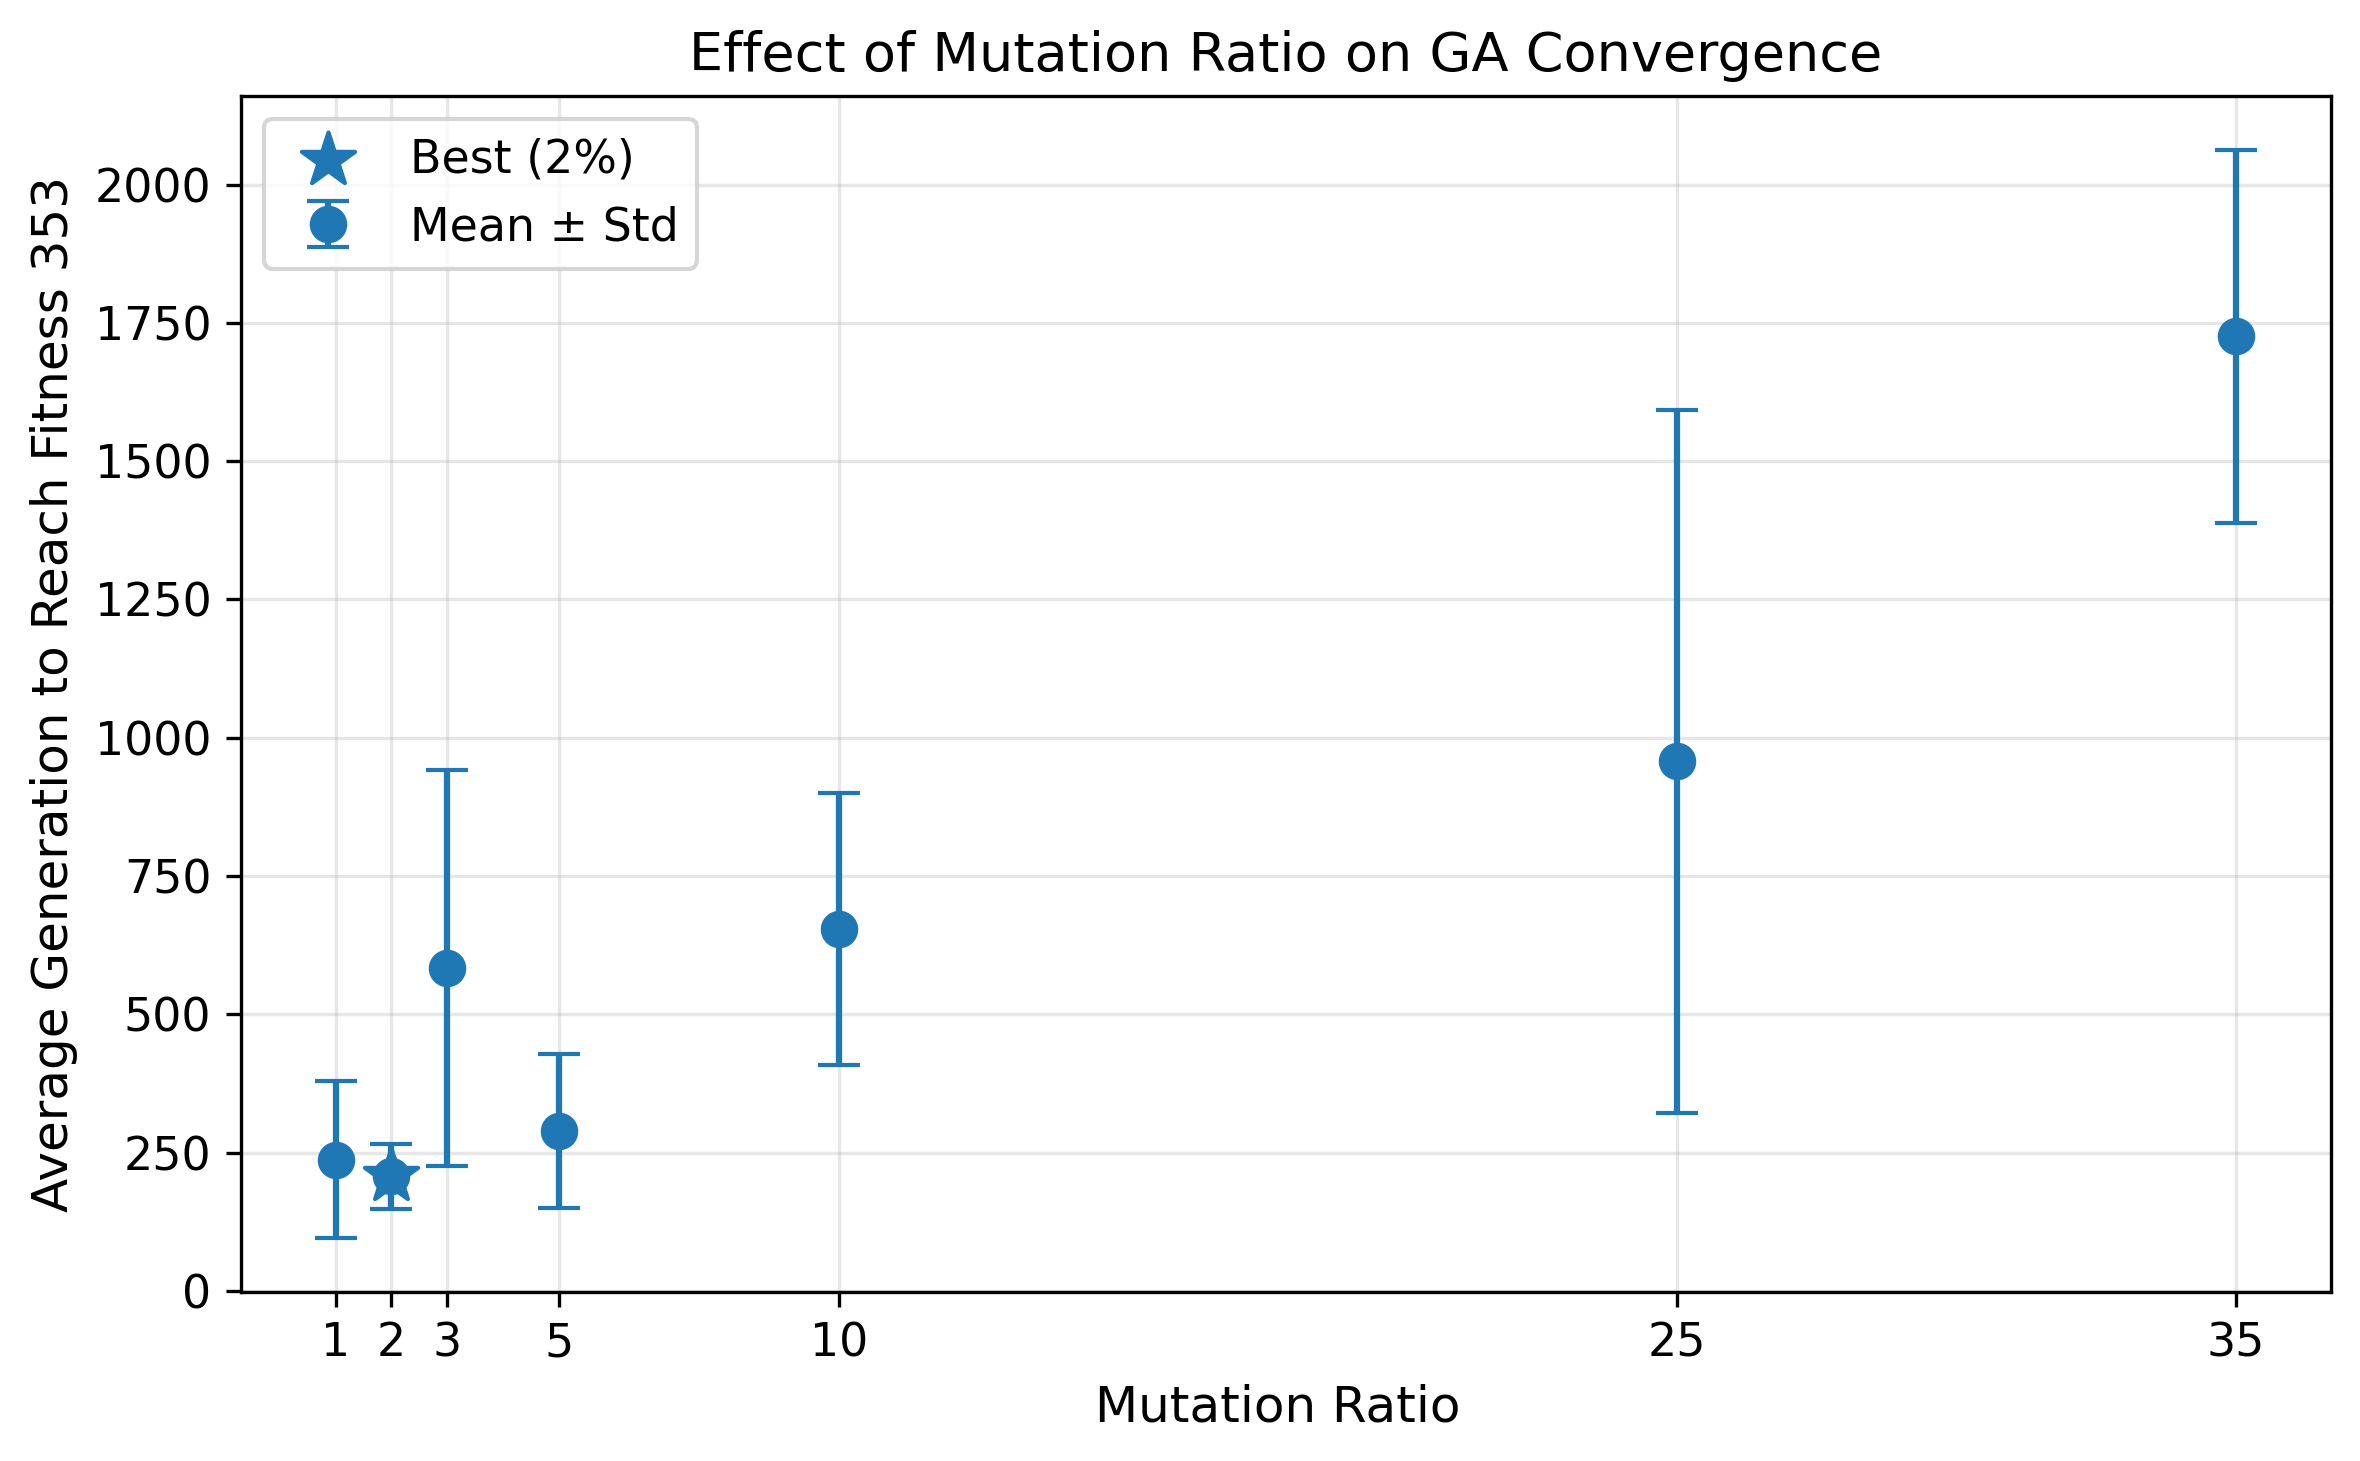

In [21]:
import matplotlib.pyplot as plt

# Use only successful runs (where 353 was found)
plot_data = (
    df_mut_rat[df_mut_rat["found"]]
    .groupby("mutation_ratio")
    .agg(
        avg_generation_353=("generation_353", "mean"),
        std_generation_353=("generation_353", "std")
    )
    .reset_index()
)

plt.figure(figsize=(8,5))

plt.errorbar(
    plot_data["mutation_ratio"],
    plot_data["avg_generation_353"],
    yerr=plot_data["std_generation_353"],
    fmt='o',
    markersize=8,
    capsize=5,
    label="Mean ± Std"
)

# Highlight best mutation ratio
best_idx = plot_data["avg_generation_353"].idxmin()

plt.scatter(
    plot_data.loc[best_idx, "mutation_ratio"],
    plot_data.loc[best_idx, "avg_generation_353"],
    s=180,
    marker="*",
    label=f"Best ({int(plot_data.loc[best_idx, 'mutation_ratio'])}%)"
)

plt.xlabel("Mutation Ratio ")
plt.ylabel("Average Generation to Reach Fitness 353")
plt.title("Effect of Mutation Ratio on GA Convergence")

plt.xticks(mut_ratios)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [32]:
import pandas as pd
import time
from concurrent.futures import ProcessPoolExecutor


N_RUNS = 10

results = []

for algorithm_name, algorithm_func in [
    ("random init", run_parallel_ga_random_init),
    ("biased mutation", run_parallel_ga),
]:

    print(f"\nRunning {algorithm_name}...")

    for run in range(N_RUNS):
        print(f"  Run {run+1}/{N_RUNS}")

        start = time.time()

        result = algorithm_func(
            n_islands=6,
            pop_per_island=80,
            n_generations_total=2400,
            migration_interval=400,
            mutation_rate=0.35,
            base_seed=run,   # different seed each run
            mutation_ratio=35,
            target_generation_wanted=True
        )

        elapsed = time.time() - start

        # adapt these names if your result dict differs
        history = result["history_best"]

        target = 353
        found = np.where(np.array(history) >= target)[0]

        if len(found) > 0:
            found_generation = found[0]
            found_time = elapsed * (found_generation / len(history))
        else:
            found_generation = np.nan
            found_time = np.nan

        results.append({
            "algorithm": algorithm_name,
            "run": run + 1,
            "target_found_generation": found_generation,
            "target_found_time": found_time,
            "runtime_total": elapsed,
            "best_fitness": max(history),
        })

df_results = pd.DataFrame(results)

df_results

2026-07-31 02:18:44,007 - INFO - Starting parallel GA with 6 islands, 400 generations per round
2026-07-31 02:18:44,152 - INFO - Round 1/6 starting



Running random init...
  Run 1/10


2026-07-31 02:19:14,650 - INFO - New global best found: 348.00
2026-07-31 02:19:14,651 - INFO - New global best found: 351.00
2026-07-31 02:19:14,653 - INFO - Round 2/6 starting


  [Runde 1/6] Beste Fitness: 351.0 | Verletzungen: 0


2026-07-31 02:19:45,150 - INFO - New global best found: 352.00
2026-07-31 02:19:45,152 - INFO - New global best found: 353.00
2026-07-31 02:19:45,153 - INFO - Target fitness 353.00 reached at generation 449 (time: 34.94s)
2026-07-31 02:19:45,154 - INFO - Round 3/6 starting


...

2026-07-31 03:19:19,306 - INFO - Round 6/6 starting


  [Runde 5/6] Beste Fitness: 353.0 | Verletzungen: 0


2026-07-31 03:19:50,395 - INFO - Parallel GA finished in 186.19 seconds


  [Runde 6/6] Beste Fitness: 353.0 | Verletzungen: 0


,algorithm,run,target_found_generation,target_found_time,runtime_total,best_fitness
0,random init,1,4461.0,56.726889,183.570807,353.0
1,random init,2,4060.0,51.267586,182.290363,353.0
2,random init,3,3659.0,46.458712,183.295426,353.0
3,random init,4,3258.0,41.226562,182.672390,353.0
4,random init,5,2857.0,36.076009,182.286760,353.0
5,random init,6,13970.0,175.936887,181.805648,353.0
6,random init,7,8064.0,101.960600,182.527681,353.0
7,random init,8,2797.0,35.205538,181.704377,353.0
8,random init,9,13352.0,168.857417,182.566332,353.0
9,random init,10,NaN,NaN,182.896395,352.0


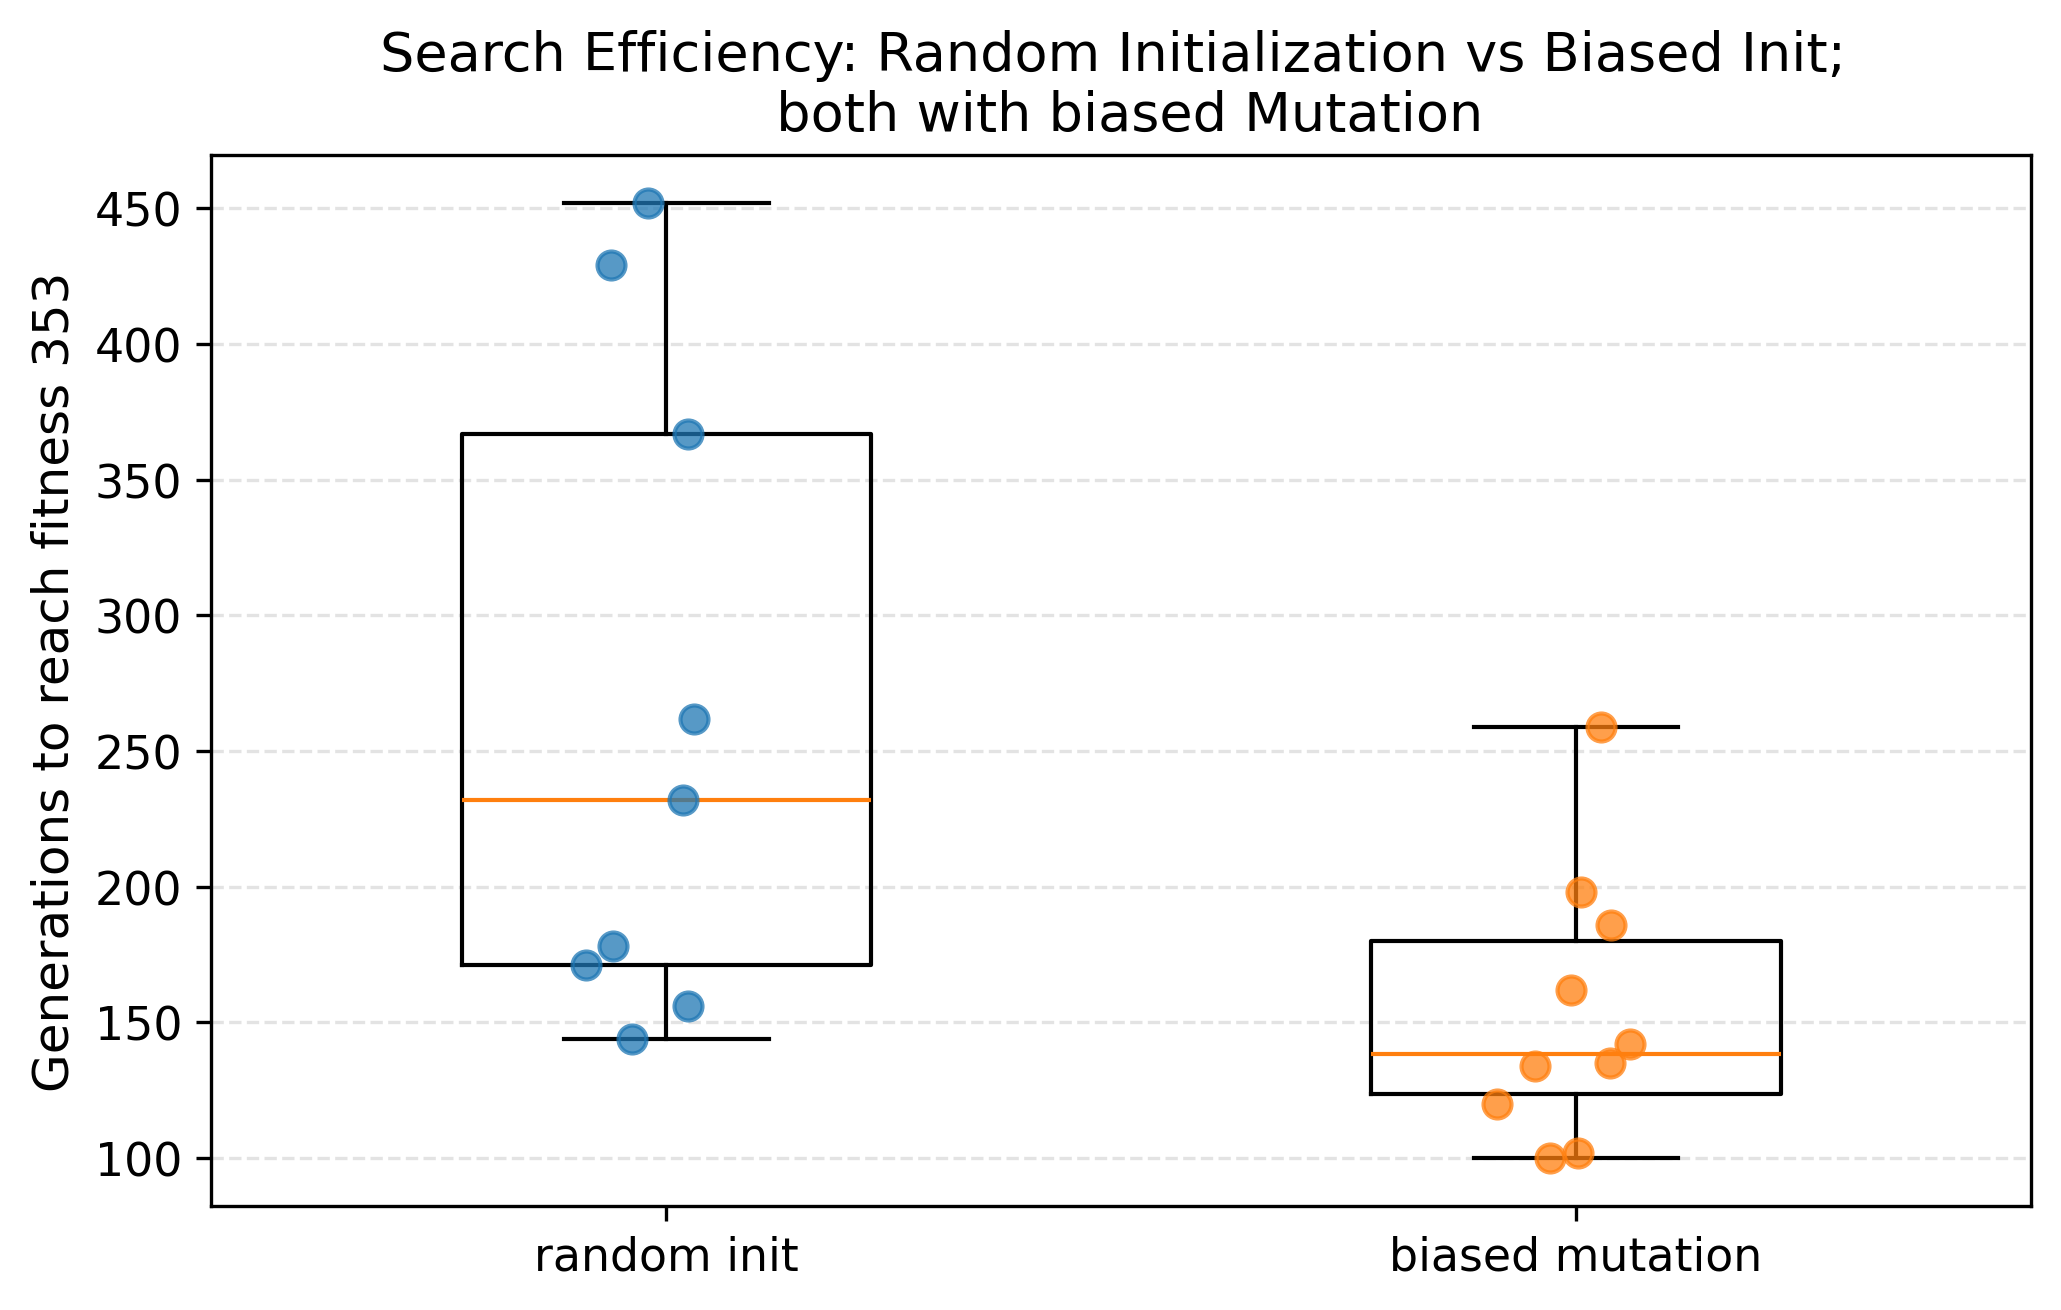

In [75]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7, 4.5), dpi=300)

algorithms = df_results["algorithm"].unique()

data = [
    df_results.loc[
        df_results["algorithm"] == alg,
        "target_found_generation"
    ].dropna()
    for alg in algorithms
]

# boxplot
plt.boxplot(
    data,
    labels=algorithms,
    widths=0.45,
    showfliers=False,
)

# individual runs
for i, values in enumerate(data, start=1):
    jitter = np.random.normal(i, 0.05, len(values))
    plt.scatter(
        jitter,
        values,
        s=45,
        alpha=0.75,
        zorder=3,
    )

plt.ylabel("Generations to reach fitness 353")
plt.title("Search Efficiency: Random Initialization vs Biased Init; \n both with biased Mutation")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()
plt.show()

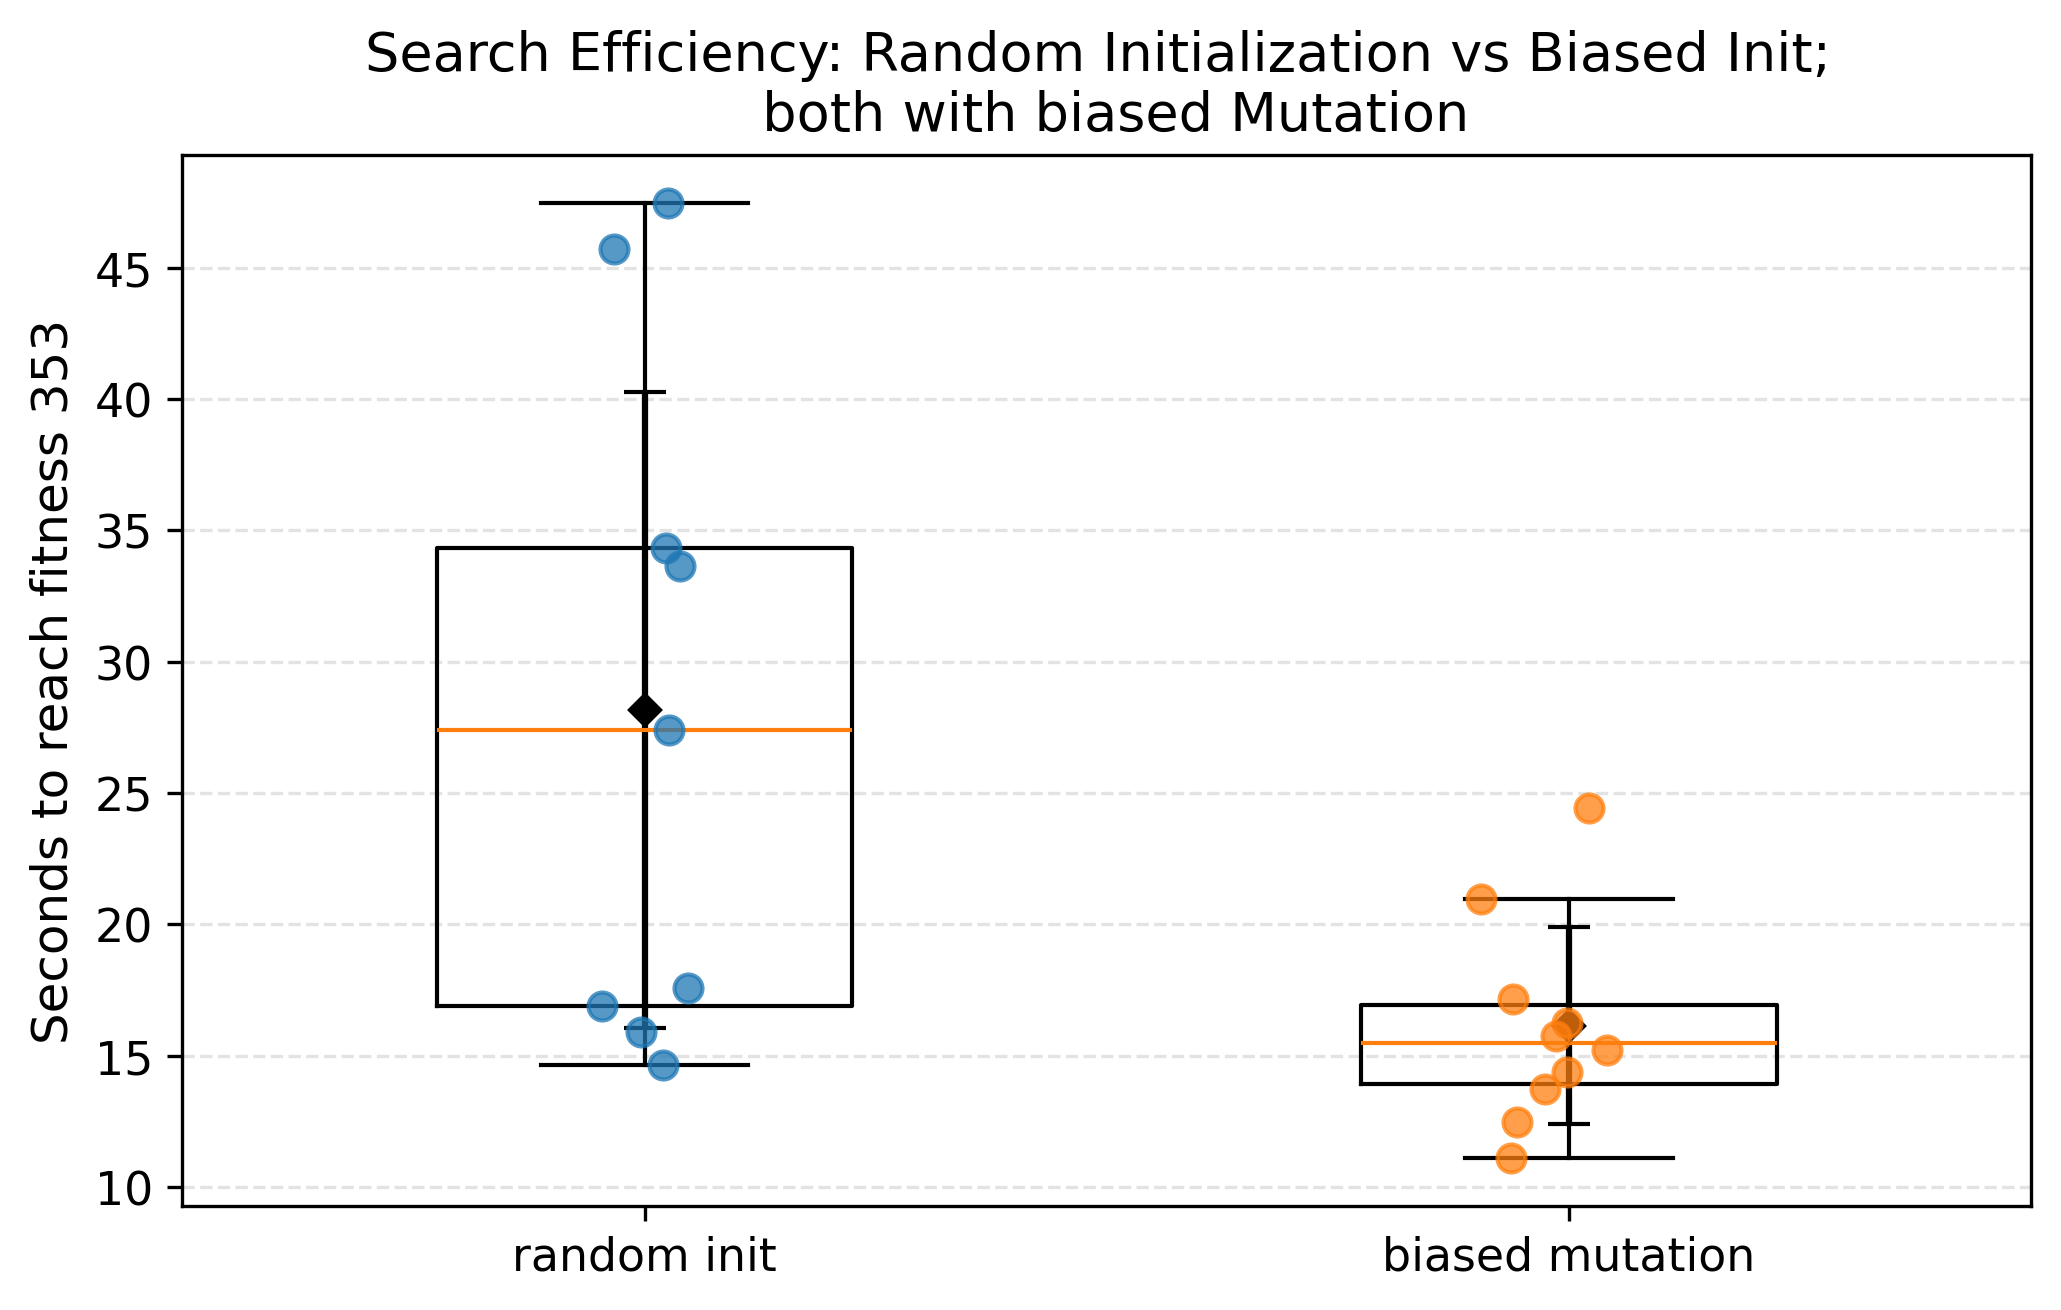

In [74]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7, 4.5), dpi=300)

algorithms = df_results["algorithm"].unique()

data = [
    df_results.loc[
        df_results["algorithm"] == alg,
        "target_found_time"
    ].dropna()
    for alg in algorithms
]

# boxplot
plt.boxplot(
    data,
    labels=algorithms,
    widths=0.45,
    showfliers=False,
)

# individual runs
for i, values in enumerate(data, start=1):
    jitter = np.random.normal(i, 0.05, len(values))
    plt.scatter(
        jitter,
        values,
        s=45,
        alpha=0.75,
        zorder=3,
    )

for i, values in enumerate(data, start=1):
    plt.errorbar(
        i,
        np.mean(values),
        yerr=np.std(values),
        fmt="D",
        color="black",
        capsize=5,
        markersize=5,
    )

plt.ylabel("Seconds to reach fitness 353")
plt.title("Search Efficiency: Random Initialization vs Biased Init; \n both with biased Mutation")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()
plt.show()

---
## 10. Korrektheitsprüfung & Abschlussbericht


In [35]:
# Slide
def full_validation(schedule, tasks, characters, scoring):
    """Vollständige Prüfung aller Constraints mit detaillierter Ausgabe."""
    print("=" * 70)
    print("  🔍 KORREKTHEITSPRÜFUNG")
    print("=" * 70)
    all_ok = True

    for task_name, slot in schedule.items():
        task      = tasks[task_name]
        timeslot  = slot["timeslot"]
        location  = slot["location"]
        attendees = slot["attendees"]
        aset      = set(attendees)
        issues    = []

        # Ort
        if location not in task.allowed_locations:
            issues.append(f"Ort '{location}' nicht erlaubt")

        # Pflichtpersonen
        for req in task.required_people:
            if req not in aset:
                issues.append(f"Pflichtperson '{req}' fehlt")

        # Verbotene Personen
        for forb in task.forbidden_people:
            if forb in aset:
                issues.append(f"Verbotene Person '{forb}' anwesend")

        # Verfügbarkeit
        unavail = [p for p in attendees if p in characters
                   and not characters[p].available_at(timeslot)]
        if unavail:
            issues.append(f"Nicht verfügbar in {timeslot}: {unavail}")

        # Personenzahl
        if len(attendees) < task.min_people:
            issues.append(f"Zu wenige Personen: {len(attendees)} < {task.min_people}")

        status = "✅" if not issues else "❌"
        if issues:
            all_ok = False
        print(f"  {status} {task_name:30s} → {timeslot:10s} @ {location}")
        for iss in issues:
            print(f"       ⚠️  {iss}")

    # Doppelbuchungen global
    from collections import Counter
    person_slots = Counter()
    for slot in schedule.values():
        for p in slot["attendees"]:
            person_slots[(p, slot["timeslot"])] += 1
    doubles = {(p, ts): n for (p, ts), n in person_slots.items() if n > 1}
    if doubles:
        all_ok = False
        print(f"\n  ❌ Doppelbuchungen:")
        for (p, ts), n in doubles.items():
            print(f"     {p} in {ts}: {n}× eingeplant")

    total_score = compute_fitness(schedule, tasks, characters, scoring)
    viol        = count_violations(schedule, tasks, characters)
    print("\n" + "=" * 70)
    print(f"  Endergebnis: {'✅ Alle Constraints erfüllt' if all_ok else '⚠️  Verletzungen vorhanden'}")
    print(f"  Gesamtscore: {total_score:.1f}")
    print(f"  Verletzungen nach Typ: {viol}")
    print("=" * 70)
    return all_ok


full_validation(result_seq["best_schedule"], TASKS, CHARACTERS, SCORING)


  🔍 KORREKTHEITSPRÜFUNG
  ✅ War Council                    → Day3_AM    @ Dragonstone
  ✅ Dragonglass Mining Plan        → Day2_AM    @ Dragonstone
  ✅ Northern Defense Council       → Day2_PM    @ Winterfell
  ✅ Alliance Negotiation           → Day4_AM    @ The Eyrie
  ✅ Royal Audience                 → Day1_PM    @ Kings Landing
  ✅ Wight Recon Mission            → Day5_AM    @ Eastwatch
  ✅ Fleet Coordination             → Day1_AM    @ Pyke
  ✅ Library Research               → Day3_AM    @ Oldtown
  ✅ Spy Network Briefing           → Day3_PM    @ Dragonstone

  Endergebnis: ✅ Alle Constraints erfüllt
  Gesamtscore: 281.0
  Verletzungen nach Typ: {'missing_required': 0, 'forbidden_present': 0, 'wrong_location': 0, 'unavailable': 0, 'double_booked': 0}


True

---
## 11. Fazit

### Datensatz `task_scheduling.json` – Charakteristika
- **Heterogene Constraints**: Pflichtpersonen, verbotene Personen, Sympathie/Antipathie, Verfügbarkeit, Ortsbeschränkungen
- **Konkurrenz um Ressourcen**: 25 Charaktere für 9 gleichzeitig zu planende Aufgaben → Doppelbuchungs-Risiko
- **Mehrdimensionale Fitness**: Basiswert + 5 Bonustypen + 5 Straftypen → direkt aus `scoring_suggestion`

### GA-Verhalten
| Aspekt | Beobachtung |
|---|---|
| **Konvergenzgeschwindigkeit** | Schnell in ersten 50–100 Generationen, dann langsame Verfeinerung |
| **Größere Populationen** | Finden bessere Lösungen, benötigen mehr Zeit |
| **Mutationsrate 0.25–0.35** | Bester Kompromiss Exploration/Exploitation |
| **Island Model** | Verhindert vorzeitige Konvergenz durch Diversitäts-Injektion via Migration |

### Mögliche Erweiterungen
- **Abhängigkeiten**: Task B erst nach Task A (Precedence Constraints)
- **Multi-Objective**: Score maximieren UND gleichzeitig Auslastung ausgleichen
- **Adaptive Mutation**: Mutationsrate sinkt mit steigender Konvergenz
- **Lokale Suche (Memetic Algorithm)**: Hybridisierung GA + Hill Climbing


In [36]:
# ══════════════════════════════════════════════════════════════
# AUFGABE 06 – Ergebnisübersicht
# ══════════════════════════════════════════════════════════════

print("=" * 65)
print("  AUFGABE 06: Zeitplanung optimieren – Genetischer Algorithmus")
print("=" * 65)

# ── a. Population zufälliger Zeitpläne ────────────────────────
print("\n📌 a. Population zufälliger Zeitpläne")
print("-" * 45)
sample_pop = [create_random_schedule(TASKS, CHARACTERS) for _ in range(5)]
for i, sched in enumerate(sample_pop):
    f = compute_fitness(sched, TASKS, CHARACTERS, SCORING)
    print(f"  Individuum {i+1}: Score = {f:.1f}")
print(f"\n  → Populationsgröße im GA: {result_seq['pop_size']} Individuen")
print(f"  → Jedes Individuum = Dict mit {len(TASKS)} Task-Zuweisungen")
print(f"     Struktur: {{task_name: {{timeslot, location, attendees}}}}")

# ── b. Kombination & Mutation über Generationen ───────────────
print("\n📌 b. Kombination & Mutation über Generationen")
print("-" * 45)
print(f"  Generationen trainiert : {result_seq['n_generations']}")
print(f"  Start-Score (Gen 0)    : {result_seq['history_best'][0]:.1f}")
print(f"  End-Score   (Gen {result_seq['n_generations']})  : {result_seq['history_best'][-1]:.1f}")
print(f"  Verbesserung           : +{result_seq['history_best'][-1] - result_seq['history_best'][0]:.1f} Punkte")
print(f"\n  Crossover : Uniform (jede Task erbt von Elter 1 oder 2)")
print(f"  Mutation  : 3 Typen")
print(f"    i)  Zeitslot verschieben  → neuer zufälliger Timeslot")
print(f"    ii) Teilnehmer ändern     → Person ersetzen / hinzufügen / entfernen")
print(f"    iii)Ort wechseln          → anderer erlaubter Ort")

# ── c. Bester Plan & Fitness-Funktion ─────────────────────────
print("\n📌 c. Bester Plan basierend auf Fitness-Funktion")
print("-" * 45)
best = result_seq["best_schedule"]
print(f"  Finale Fitness : {result_seq['best_fitness']:.1f}")
viol = count_violations(best, TASKS, CHARACTERS)
print(f"  Verletzungen   : {sum(viol.values())}  {viol}")
print()

slot_order = {s: i for i, s in enumerate(TIMESLOTS)}
for task_name, slot in sorted(best.items(), key=lambda x: slot_order.get(x[1]["timeslot"], 99)):
    task     = TASKS[task_name]
    aset     = set(slot["attendees"])
    loc_ok   = "✅" if slot["location"] in task.allowed_locations else "❌"
    ts_pref  = "⭐" if slot["timeslot"] in task.preferred_timeslots else "  "
    missing  = [r for r in task.required_people if r not in aset]
    miss_str = f"  ⚠️  Fehlt: {missing}" if missing else ""
    print(f"  {loc_ok}{ts_pref} [{slot['timeslot']:10s}] {task_name:30s} @ {slot['location']}")
    print(f"        👥 {', '.join(slot['attendees'])}{miss_str}")

# ── Constraints-Nachweis ──────────────────────────────────────
print("\n📌 Constraints – Nachweis gültiger Lösungen")
print("-" * 45)
all_ok = True
for task_name, slot in best.items():
    task = TASKS[task_name]
    aset = set(slot["attendees"])
    issues = []
    if slot["location"] not in task.allowed_locations:
        issues.append("Falscher Ort")
    for r in task.required_people:
        if r not in aset: issues.append(f"'{r}' fehlt")
    for f in task.forbidden_people:
        if f in aset: issues.append(f"'{f}' verboten aber anwesend")
    for p in slot["attendees"]:
        if p in CHARACTERS and not CHARACTERS[p].available_at(slot["timeslot"]):
            issues.append(f"'{p}' nicht verfügbar")
    status = "✅ OK" if not issues else "❌ " + " | ".join(issues)
    if issues: all_ok = False
    print(f"  {status:12s} → {task_name}")

print()
print("  " + ("✅ Alle Constraints erfüllt – Lösung ist gültig!" if all_ok else "❌ Verletzungen vorhanden"))
print("=" * 65)

  AUFGABE 06: Zeitplanung optimieren – Genetischer Algorithmus

📌 a. Population zufälliger Zeitpläne
---------------------------------------------
  Individuum 1: Score = -565.0
  Individuum 2: Score = -426.0
  Individuum 3: Score = -305.0
  Individuum 4: Score = -1269.0
  Individuum 5: Score = -662.0

  → Populationsgröße im GA: 200 Individuen
  → Jedes Individuum = Dict mit 9 Task-Zuweisungen
     Struktur: {task_name: {timeslot, location, attendees}}

📌 b. Kombination & Mutation über Generationen
---------------------------------------------
  Generationen trainiert : 2400
  Start-Score (Gen 0)    : 241.0
  End-Score   (Gen 2400)  : 281.0
  Verbesserung           : +40.0 Punkte

  Crossover : Uniform (jede Task erbt von Elter 1 oder 2)
  Mutation  : 3 Typen
    i)  Zeitslot verschieben  → neuer zufälliger Timeslot
    ii) Teilnehmer ändern     → Person ersetzen / hinzufügen / entfernen
    iii)Ort wechseln          → anderer erlaubter Ort

📌 c. Bester Plan basierend auf Fitness-Funk

In [15]:

def run_parallel_ga_random_init(n_islands=4, pop_per_island=80,
                    n_generations_total=400, migration_interval=100,
                    crossover_rate=0.85, mutation_rate=0.30,
                    mutation_ratio=50, elitism=6, tournament_k=5,
                    base_seed=42, pop=None,  target_fitness=353,target_generation_wanted=False ):

    tasks_raw = DATA["tasks"]
    chars_raw = DATA["characters"]
    locations = DATA["locations"]

    n_rounds = max(1, n_generations_total // migration_interval)
    gens_per_round = migration_interval
    immigrants = [[] for _ in range(n_islands)]
    global_best_s = None
    global_best_f = -1e9
    hist_global = []
    island_pop = []
    target_fitness=353
    target_found_generation = None
    target_found_time = None

    t0 = time.perf_counter()
    logger.info("Starting parallel GA with %d islands, %d generations per round", n_islands, gens_per_round)

    manager = mp.Manager()
    log_queue = manager.Queue()

# Slide 
    for rnd in range(n_rounds):
        logger.info("Round %d/%d starting", rnd + 1, n_rounds)

        args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed*65 + rnd * 100 + i*54,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
            )
            for i in range(n_islands)
        ]

        if target_generation_wanted:
            args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed*65 + rnd * 100 + i*54,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
                target_generation_wanted
            )
            for i in range(n_islands)
        ]

        #logger.info("Number of args to start: %d", len(args_list[0]))

        with ProcessPoolExecutor(max_workers=n_islands) as executor:
            results = list(executor.map(run_island_worker_random_init, args_list))

        _drain_worker_logs(log_queue)

        all_emigrants = []
        if target_generation_wanted:
            for i, (best_s, best_f, hist, emigrants, result_pop, target_generation, target_time) in enumerate(results):
                hist_global.extend(hist)
                all_emigrants.append(emigrants)
                island_pop.append(result_pop)
                #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

                if best_f > global_best_f:
                    global_best_f = best_f
                    global_best_s = copy.deepcopy(best_s)

                    logger.info("New global best found: %.2f", global_best_f)
                    
                if best_f >= target_fitness:
                    candidate_generation = target_generation + rnd * gens_per_round
                    candidate_time = target_time - t0

                    if (
                        target_found_generation is None
                        or candidate_generation < target_found_generation
                    ):
                        target_found_generation = candidate_generation
                        target_found_time = candidate_time

                        logger.info(
                            "Target fitness %.2f reached at generation %d (time: %.2fs)",
                            target_fitness,
                            target_found_generation,
                            target_found_time
                        )
        else:
            for i, (best_s, best_f, hist, emigrants, result_pop) in enumerate(results):
                hist_global.extend(hist)
                all_emigrants.append(emigrants)
                island_pop.append(result_pop)
                #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

                if best_f > global_best_f:
                    global_best_f = best_f
                    global_best_s = copy.deepcopy(best_s)

                    logger.info("New global best found: %.2f", global_best_f)


        immigrants = [all_emigrants[(i - 1) % n_islands] for i in range(n_islands)]
        #logger.info("Migration list prepared for next round: %d emigrants per island", len(all_emigrants[0]) if all_emigrants else 0)

        viol = sum(count_violations(global_best_s, TASKS, CHARACTERS).values())
        print(f"  [Runde {rnd+1}/{n_rounds}] Beste Fitness: {global_best_f:.1f} | Verletzungen: {viol}")

    _drain_worker_logs(log_queue)
    manager.shutdown()
    elapsed = time.perf_counter() - t0
    logger.info("Parallel GA finished in %.2f seconds", elapsed)

    return {
    "best_schedule": global_best_s,
    "best_fitness": global_best_f,
    "history_best": hist_global,
    "elapsed": elapsed,
    "target_found_generation": target_found_generation,
    "target_found_time": target_found_time,

    "n_islands": n_islands,
}

In [14]:

def run_parallel_ga(n_islands=4, pop_per_island=80,
                    n_generations_total=400, migration_interval=100,
                    crossover_rate=0.85, mutation_rate=0.30,
                    mutation_ratio=50, elitism=6, tournament_k=5,
                    base_seed=42, pop=None,  target_fitness=353,target_generation_wanted=False ):

    tasks_raw = DATA["tasks"]
    chars_raw = DATA["characters"]
    locations = DATA["locations"]

    n_rounds = max(1, n_generations_total // migration_interval)
    gens_per_round = migration_interval
    immigrants = [[] for _ in range(n_islands)]
    global_best_s = None
    global_best_f = -1e9
    hist_global = []
    island_pop = []
    target_fitness=353
    target_found_generation = None
    target_found_time = None

    t0 = time.perf_counter()
    logger.info("Starting parallel GA with %d islands, %d generations per round", n_islands, gens_per_round)

    manager = mp.Manager()
    log_queue = manager.Queue()

# Slide 
    for rnd in range(n_rounds):
        logger.info("Round %d/%d starting", rnd + 1, n_rounds)

        args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed*65 + rnd * 100 + i*54,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
            )
            for i in range(n_islands)
        ]

        if target_generation_wanted:
            args_list = [
            (
                tasks_raw,
                chars_raw,
                locations,
                SCORING,
                pop_per_island,
                gens_per_round,
                crossover_rate,
                mutation_rate,
                mutation_ratio,
                elitism,
                tournament_k,
                base_seed*65 + rnd * 100 + i*54,
                immigrants[i],
                island_pop[i] if island_pop else None,
                log_queue,
                target_generation_wanted
            )
            for i in range(n_islands)
        ]

        #logger.info("Number of args to start: %d", len(args_list[0]))

        with ProcessPoolExecutor(max_workers=n_islands) as executor:
            results = list(executor.map(run_island, args_list))

        _drain_worker_logs(log_queue)

        all_emigrants = []
        if target_generation_wanted:
            for i, (best_s, best_f, hist, emigrants, result_pop, target_generation, target_time) in enumerate(results):
                hist_global.extend(hist)
                all_emigrants.append(emigrants)
                island_pop.append(result_pop)
                #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

                if best_f > global_best_f:
                    global_best_f = best_f
                    global_best_s = copy.deepcopy(best_s)

                    logger.info("New global best found: %.2f", global_best_f)

                if best_f >= target_fitness:
                    candidate_generation = target_generation + rnd * gens_per_round
                    candidate_time = target_time - t0

                    if (
                        target_found_generation is None
                        or candidate_generation < target_found_generation
                    ):
                        target_found_generation = candidate_generation
                        target_found_time = candidate_time

                        logger.info(
                            "Target fitness %.2f reached at generation %d (time: %.2fs)",
                            target_fitness,
                            target_found_generation,
                            target_found_time
                        )
                
        else:
            for i, (best_s, best_f, hist, emigrants, result_pop) in enumerate(results):
                hist_global.extend(hist)
                all_emigrants.append(emigrants)
                island_pop.append(result_pop)
                #logger.info("Island %d finished round %d with best fitness %.2f", i + 1, rnd + 1, best_f)

                if best_f > global_best_f:
                    global_best_f = best_f
                    global_best_s = copy.deepcopy(best_s)

                    logger.info("New global best found: %.2f", global_best_f)


        immigrants = [all_emigrants[(i - 1) % n_islands] for i in range(n_islands)]
        #logger.info("Migration list prepared for next round: %d emigrants per island", len(all_emigrants[0]) if all_emigrants else 0)

        viol = sum(count_violations(global_best_s, TASKS, CHARACTERS).values())
        print(f"  [Runde {rnd+1}/{n_rounds}] Beste Fitness: {global_best_f:.1f} | Verletzungen: {viol}")

    _drain_worker_logs(log_queue)
    manager.shutdown()
    elapsed = time.perf_counter() - t0
    logger.info("Parallel GA finished in %.2f seconds", elapsed)

    return {
    "best_schedule": global_best_s,
    "best_fitness": global_best_f,
    "history_best": hist_global,
    "elapsed": elapsed,
    "target_found_generation": target_found_generation,
    "target_found_time": target_found_time,

    "n_islands": n_islands,
}


print("✅ Parallele GA-Funktion bereit (concurrent.futures)")

✅ Parallele GA-Funktion bereit (concurrent.futures)


In [ ]:
# experimental
import pandas as pd
import time
import numpy as np


N_RUNS = 10

results = []

for algorithm_name, algorithm_func in [
    ("random init", run_parallel_ga_random_init),
    ("biased mutation", run_parallel_ga),
]:

    print(f"\nRunning {algorithm_name}...")

    for run in range(N_RUNS):
        print(f"  Run {run+1}/{N_RUNS}")

        start = time.time()

        result = algorithm_func(
            n_islands=6,
            pop_per_island=80,
            n_generations_total=600,
            migration_interval=100,
            mutation_rate=0.35,
            base_seed=run,
            mutation_ratio=1,
            target_generation_wanted=True
        )

        elapsed = time.time() - start

        history = result["history_best"]

        # IMPORTANT:
        # Use the generation calculated inside the GA.
        # Do NOT calculate it from history_best.
        found_generation = result["target_found_generation"]
        found_time = result["target_found_time"]

        if found_generation is None:
            found_generation = np.nan
            found_time = np.nan

        results.append({
            "algorithm": algorithm_name,
            "run": run + 1,
            "target_found_generation": found_generation,
            "target_found_time": found_time,
            "runtime_total": elapsed,
            "best_fitness": max(history),
        })


df_results = pd.DataFrame(results)

df_results

2026-07-31 15:42:39,206 - INFO - Starting parallel GA with 6 islands, 100 generations per round



Running random init...
  Run 1/10


2026-07-31 15:42:39,494 - INFO - Round 1/6 starting
2026-07-31 15:42:53,531 - INFO - New global best found: 317.00
2026-07-31 15:42:53,534 - INFO - New global best found: 335.00
2026-07-31 15:42:53,538 - INFO - New global best found: 340.00
2026-07-31 15:42:53,541 - INFO - Round 2/6 starting


  [Runde 1/6] Beste Fitness: 340.0 | Verletzungen: 0


2026-07-31 15:43:09,282 - INFO - New global best found: 348.00
2026-07-31 15:43:09,284 - INFO - New global best found: 349.00
2026-07-31 15:43:09,286 - INFO - New global best found: 350.00
2026-07-31 15:43:09,290 - INFO - New global best found: 351.00
2026-07-31 15:43:09,293 - INFO - Round 3/6 starting


...

2026-07-31 16:02:55,588 - INFO - Round 6/6 starting


  [Runde 5/6] Beste Fitness: 353.0 | Verletzungen: 0


2026-07-31 16:03:06,171 - INFO - Parallel GA finished in 64.76 seconds


  [Runde 6/6] Beste Fitness: 353.0 | Verletzungen: 0


,algorithm,run,target_found_generation,target_found_time,runtime_total,best_fitness
0,random init,1,232.0,34.332448,74.071343,353.0
1,random init,2,262.0,27.411316,63.815577,353.0
2,random init,3,156.0,15.903593,60.263191,353.0
3,random init,4,429.0,45.709960,61.628134,353.0
4,random init,5,452.0,47.474370,62.119962,353.0
5,random init,6,NaN,NaN,59.666991,351.0
6,random init,7,144.0,14.639686,61.552615,353.0
7,random init,8,178.0,16.884484,63.249642,353.0
8,random init,9,171.0,17.565573,59.778225,353.0
9,random init,10,367.0,33.629830,52.820129,353.0


In [76]:
summary = (
    df_results
    .groupby("algorithm")
    .agg(
        runs=("run", "count"),
        success_rate=("target_found_generation", lambda x: x.notna().mean() * 100),

        avg_generations=("target_found_generation", "mean"),
        std_generations=("target_found_generation", "std"),

        avg_time=("target_found_time", "mean"),
        std_time=("target_found_time", "std"),

        avg_runtime=("runtime_total", "mean"),
        std_runtime=("runtime_total", "std"),
    )
    .round(2)
)

print(summary)

                 runs  success_rate  avg_generations  std_generations  \
algorithm                                                               
biased mutation    10         100.0           153.80            49.14   
random init        10          90.0           265.67           120.57   

                 avg_time  std_time  avg_runtime  std_runtime  
algorithm                                                      
biased mutation     16.15      3.97         60.8         3.89  
random init         28.17     12.86         61.9         5.25  
